<a href="https://colab.research.google.com/github/donggyu3/trash-classfication/blob/main/trash_classfication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import time
import random
import zipfile
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from sklearn.metrics import confusion_matrix, classification_report


# 1. 재현성을 위한 시드 고정 및 GPU 설정
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("현재 사용 장치:", device)


# 2. 실행 환경 자동 감지 (Colab vs 로컬 Jupyter) 및 경로 설정
IS_COLAB = os.path.exists("/content")

if IS_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive"):
        drive.mount('/content/drive')
    zip_path = "/content/drive/MyDrive/Colab Notebooks/archive.zip"
    extract_path = "/content/data"
else:
    # 다른 사람(로컬 PC)이 실행할 때의 기본 경로
    zip_path = "./archive.zip"
    extract_path = "./data"


# 3. 클래스 폴더 탐색 함수
class_names = {
    "battery", "batteries", "biological", "cardboard",
    "clothes", "shoes", "green-glass", "brown-glass",
    "white-glass", "metal", "paper", "plastic", "trash"
}

def normalize_name(name):
    return name.lower().replace("_", "-").replace(" ", "-")

def find_data_dir(base_path):
    if not os.path.exists(base_path):
        return None

    for root, dirs, files in os.walk(base_path):
        normalized = {normalize_name(d) for d in dirs}
        if len(normalized & class_names) == 12:
            return root

    return None


# 4. 기존 압축 해제 데이터 확인
DATA_DIR = find_data_dir(extract_path)
full_dataset = None

if DATA_DIR is not None:
    try:
        candidate = ImageFolder(DATA_DIR)
        if len(candidate.classes) == 12 and len(candidate.samples) > 0:
            full_dataset = candidate
            print("기존 압축 해제 데이터 재사용!")
            print("이미지 개수:", len(full_dataset))
    except Exception:
        full_dataset = None


# 5. 데이터가 없는 경우 ZIP 파일에서 압축 해제 (OS 무관 Python zipfile 사용)
if full_dataset is None:
    if not os.path.exists(zip_path):
        raise FileNotFoundError(
            f"데이터셋을 찾을 수 없습니다.\n"
            f"'{zip_path}' 위치에 Kaggle Garbage Classification ZIP 파일(archive.zip)을 두거나,\n"
            f"'{extract_path}' 폴더 안에 12개 클래스 폴더를 배치해 주세요."
        )

    image_extensions = {
        ".jpg", ".jpeg", ".png", ".bmp",
        ".webp", ".tif", ".tiff", ".ppm", ".pgm"
    }

    with zipfile.ZipFile(zip_path, "r") as z:
        zip_image_count = sum(
            Path(info.filename).suffix.lower() in image_extensions
            and "__MACOSX" not in Path(info.filename).parts
            and not Path(info.filename).name.startswith("._")
            for info in z.infolist()
            if not info.is_dir()
        )
    print("ZIP 내부 이미지 개수:", zip_image_count)

    print("압축 해제가 필요합니다. 압축 해제 시작...")
    if os.path.exists(extract_path):
        shutil.rmtree(extract_path)
    os.makedirs(extract_path, exist_ok=True)

    start_time = time.time()
    # 리눅스 unzip 대신 파이썬 내장 zipfile을 써서 Windows/Mac에서도 동일하게 작동
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

    print("압축 해제 완료!")
    print(f"소요 시간: {time.time() - start_time:.1f}초")

    DATA_DIR = find_data_dir(extract_path)
    assert DATA_DIR is not None, "데이터셋 폴더를 찾지 못했습니다."

    full_dataset = ImageFolder(DATA_DIR)


# 6. 최종 데이터 및 환경 확인
classes = full_dataset.classes

assert len(classes) == 12, "클래스가 12개가 아닙니다."
assert len(full_dataset) > 0, "이미지가 없습니다."

print("\n===== 데이터 및 환경 확인 결과 =====")
print("현재 사용 장치:", device)
print("데이터 경로:", DATA_DIR)
print("클래스 수:", len(classes))
print("클래스 목록:", classes)
print("전체 이미지 수:", len(full_dataset))

현재 사용 장치: cuda
기존 압축 해제 데이터 재사용!
이미지 개수: 15515

===== 데이터 및 환경 확인 결과 =====
현재 사용 장치: cuda
데이터 경로: /content/data/garbage_classification
클래스 수: 12
클래스 목록: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
전체 이미지 수: 15515


===== 클래스별 이미지 개수 =====
      Class  Image Count
    battery          945
 biological          985
brown-glass          607
  cardboard          891
    clothes         5325
green-glass          629
      metal          769
      paper         1050
    plastic          865
      shoes         1977
      trash          697
white-glass          775

전체 이미지: 15515장 | 최소: 607장 | 최대: 5325장


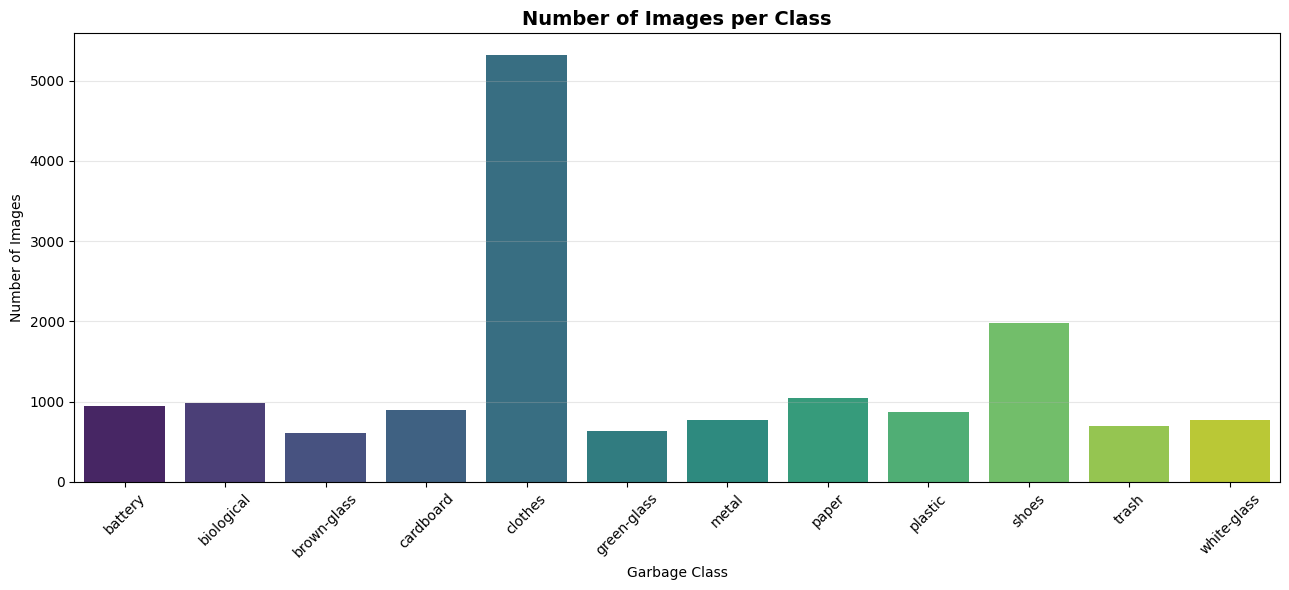

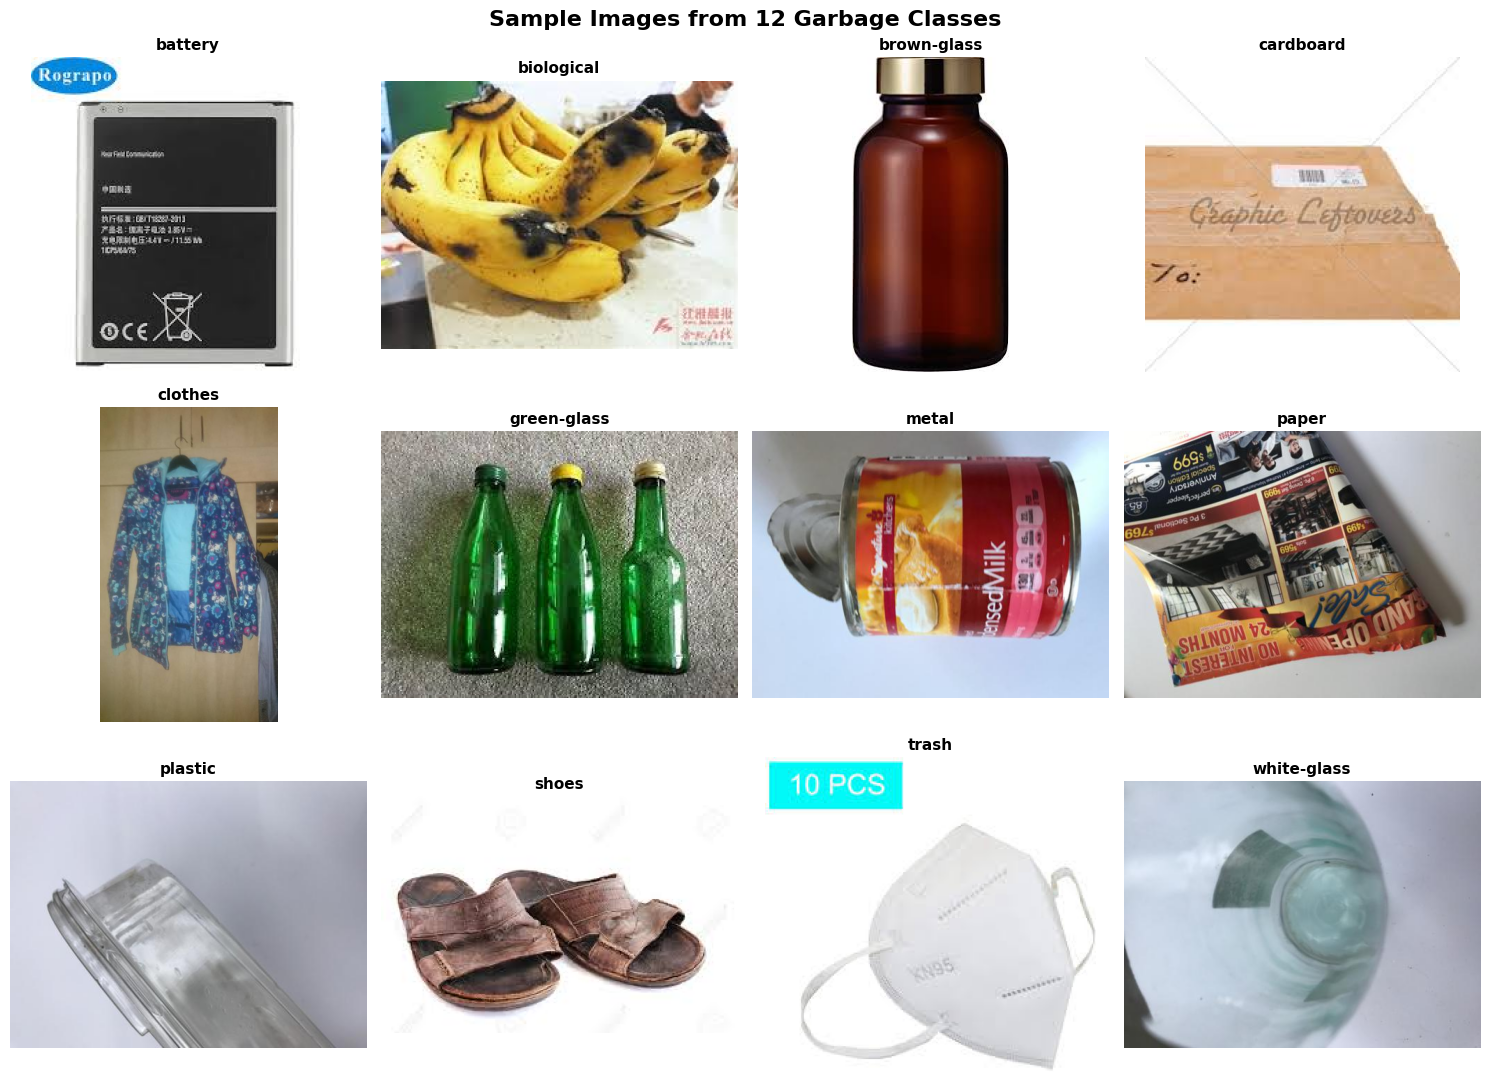


===== 원본 이미지 크기 분포 (상위 10개) =====
(400, 533): 54장
(512, 384): 50장
(225, 225): 28장
(400, 534): 20장
(275, 183): 16장
(194, 259): 7장
(259, 194): 7장
(533, 400): 7장
(400, 711): 6장
(534, 400): 5장

===== 데이터 분할 결과 =====
학습(Train): 10860장 (70.00%)
검증(Val)  : 2327장 (15.00%)
평가(Test) : 2328장 (15.00%)

===== 클래스별 데이터 분할 결과 =====
      Class  Train  Validation  Test
    battery    661         142   142
 biological    689         148   148
brown-glass    425          91    91
  cardboard    624         133   134
    clothes   3727         799   799
green-glass    440          95    94
      metal    538         116   115
      paper    735         157   158
    plastic    606         129   130
      shoes   1384         296   297
      trash    488         105   104
white-glass    543         116   116


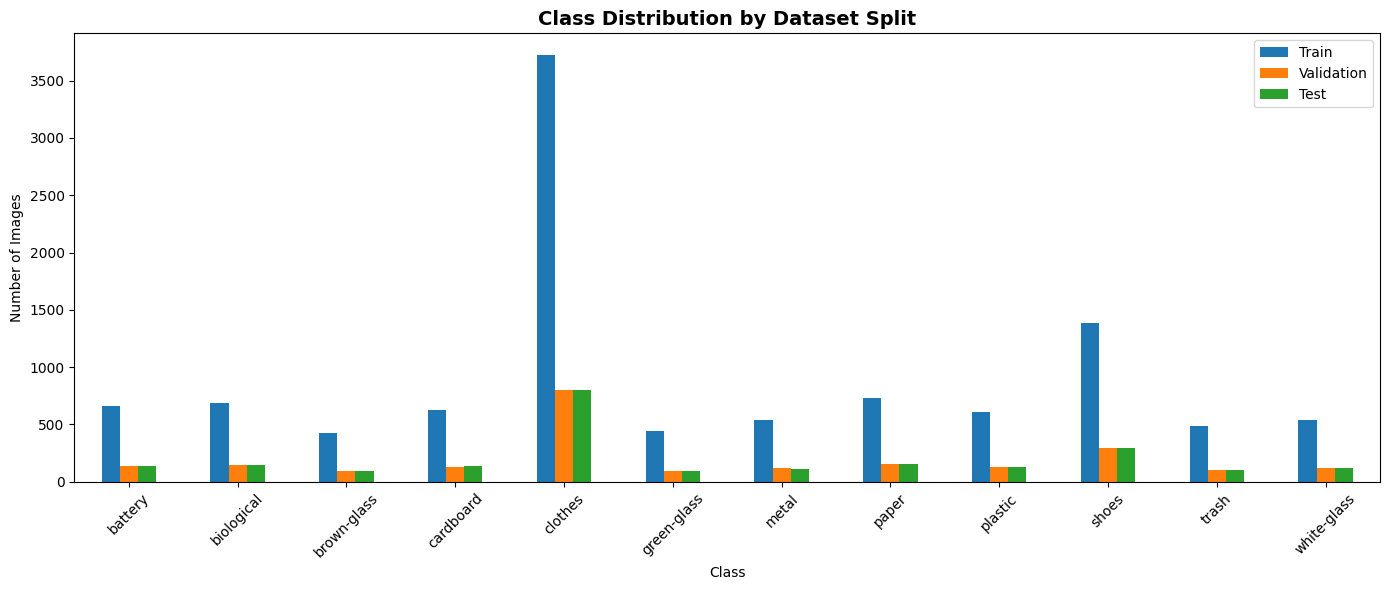


===== Batch 확인 결과 =====
이미지 Tensor 크기: torch.Size([32, 3, 160, 160])
정답 Label 크기: torch.Size([32])
이미지 자료형: torch.float32
첫 번째 이미지의 클래스: paper


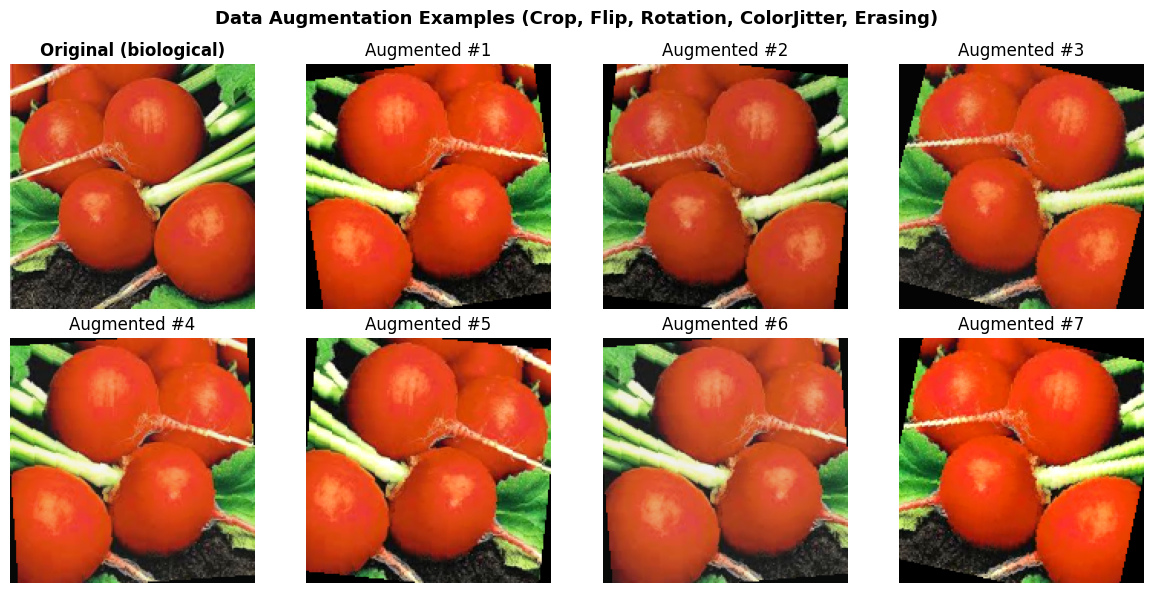


===== 2단계 데이터 준비 완료 =====


In [9]:
# ============================================================
# 2단계: 데이터 분석(EDA), 층화 분할, 맞춤형 증강 및 DataLoader 구성
# ============================================================

from PIL import Image
from collections import Counter
from sklearn.model_selection import train_test_split

# 1번 셀 실행 여부 확인
assert "full_dataset" in globals(), "먼저 1번 셀을 실행하세요."

random.seed(SEED)
np.random.seed(SEED)

classes = full_dataset.classes
labels = np.array(full_dataset.targets)


# ------------------------------------------------------------
# 1. 클래스별 이미지 개수 확인 및 불균형 보정 가중치 계산
# ------------------------------------------------------------
class_counts = np.bincount(labels, minlength=len(classes))
class_df = pd.DataFrame({
    "Class": classes,
    "Image Count": class_counts
})

print("===== 클래스별 이미지 개수 =====")
print(class_df.to_string(index=False))
print(f"\n전체 이미지: {len(full_dataset)}장 | 최소: {class_counts.min()}장 | 최대: {class_counts.max()}장")

# 소수 클래스 정확도 향상을 위한 손실함수 가중치 계산 (3~4번 셀에서 사용)
counts_tensor = torch.tensor(class_counts, dtype=torch.float32)
class_weights = (counts_tensor.sum() / (len(classes) * counts_tensor)).to(device)


# ------------------------------------------------------------
# 2. 클래스별 이미지 분포 그래프 저장 (보고서 그림 1)
# ------------------------------------------------------------
plt.figure(figsize=(13, 6))
sns.barplot(data=class_df, x="Class", y="Image Count", hue="Class", palette="viridis", legend=False)
plt.title("Number of Images per Class", fontsize=14, fontweight="bold")
plt.xlabel("Garbage Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("01_class_distribution.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# 3. 클래스별 실제 이미지 샘플 시각화 저장 (보고서 그림 2)
# ------------------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
axes = axes.flatten()

for class_idx, class_name in enumerate(classes):
    class_indices = np.where(labels == class_idx)[0]
    sample_idx = random.choice(class_indices.tolist())
    image_path, _ = full_dataset.samples[sample_idx]
    img = full_dataset.loader(image_path)

    axes[class_idx].imshow(img)
    axes[class_idx].set_title(class_name, fontsize=11, fontweight="bold")
    axes[class_idx].axis("off")

plt.suptitle("Sample Images from 12 Garbage Classes", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("02_class_samples.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# 4. 원본 이미지 크기 분포 확인 (무작위 300장)
# ------------------------------------------------------------
sample_indices = random.sample(range(len(full_dataset)), min(300, len(full_dataset)))
image_sizes = []

for idx in sample_indices:
    image_path, _ = full_dataset.samples[idx]
    with Image.open(image_path) as img:
        image_sizes.append(img.size)

size_counts = Counter(image_sizes)
print("\n===== 원본 이미지 크기 분포 (상위 10개) =====")
for size, count in size_counts.most_common(10):
    print(f"{size}: {count}장")


# ------------------------------------------------------------
# 5. 층화 분할 (Train 70% / Validation 15% / Test 15%)
# ------------------------------------------------------------
all_indices = np.arange(len(full_dataset))

train_indices, temp_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_indices]
)

print("\n===== 데이터 분할 결과 =====")
print(f"학습(Train): {len(train_indices)}장 ({len(train_indices)/len(full_dataset)*100:.2f}%)")
print(f"검증(Val)  : {len(val_indices)}장 ({len(val_indices)/len(full_dataset)*100:.2f}%)")
print(f"평가(Test) : {len(test_indices)}장 ({len(test_indices)/len(full_dataset)*100:.2f}%)")


# ------------------------------------------------------------
# 6. 클래스별 데이터 분할 분포 그래프 저장 (보고서 그림 3)
# ------------------------------------------------------------
split_df = pd.DataFrame({
    "Class": classes,
    "Train": np.bincount(labels[train_indices], minlength=len(classes)),
    "Validation": np.bincount(labels[val_indices], minlength=len(classes)),
    "Test": np.bincount(labels[test_indices], minlength=len(classes))
})

print("\n===== 클래스별 데이터 분할 결과 =====")
print(split_df.to_string(index=False))

split_df.set_index("Class").plot(kind="bar", figsize=(14, 6))
plt.title("Class Distribution by Dataset Split", fontsize=14, fontweight="bold")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("03_split_distribution.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# 7. 이미지 전처리 및 맞춤형 데이터 증강 파이프라인 (160 x 160)
# ------------------------------------------------------------
IMAGE_SIZE = 160
BATCH_SIZE = 32
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 검증/테스트 및 Baseline 학습용 기본 변환
basic_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# 유리병 색상 보존 및 현실적 변형을 반영한 최적 증강 파이프라인
aug_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 16, IMAGE_SIZE + 16)),
    transforms.RandomCrop((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(
        p=0.15,
        scale=(0.02, 0.10)
    )
])


# ------------------------------------------------------------
# 8. 사용자 정의 Dataset 및 DataLoader 구성
# ------------------------------------------------------------
class GarbageDataset(Dataset):
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = int(self.indices[idx])
        image_path, label = self.base_dataset.samples[real_idx]
        image = self.base_dataset.loader(image_path)

        if self.transform is not None:
            image = self.transform(image)

        return image, label


NUM_WORKERS = 2

train_dataset = GarbageDataset(full_dataset, train_indices, basic_transform)
val_dataset = GarbageDataset(full_dataset, val_indices, basic_transform)
test_dataset = GarbageDataset(full_dataset, test_indices, basic_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

images, batch_labels = next(iter(train_loader))
print("\n===== Batch 확인 결과 =====")
print("이미지 Tensor 크기:", images.shape)
print("정답 Label 크기:", batch_labels.shape)
print("이미지 자료형:", images.dtype)
print("첫 번째 이미지의 클래스:", classes[batch_labels[0].item()])


# ------------------------------------------------------------
# 9. 맞춤형 데이터 증강 적용 예시 시각화 저장 (보고서 그림 4)
# ------------------------------------------------------------
def denormalize(tensor):
    img = tensor.clone().cpu().numpy().transpose(1, 2, 0)
    img = img * np.array(STD) + np.array(MEAN)
    return np.clip(img, 0, 1)

sample_path, sample_lbl = full_dataset.samples[int(train_indices[0])]
raw_img = full_dataset.loader(sample_path)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(raw_img.resize((IMAGE_SIZE, IMAGE_SIZE)))
axes[0, 0].set_title(f"Original ({classes[sample_lbl]})", fontweight="bold")
axes[0, 0].axis("off")

for i, ax in enumerate(axes.flat[1:], start=1):
    ax.imshow(denormalize(aug_transform(raw_img)))
    ax.set_title(f"Augmented #{i}")
    ax.axis("off")

plt.suptitle("Data Augmentation Examples (Crop, Flip, Rotation, ColorJitter, Erasing)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("04_augmentation_samples.png", dpi=300)
plt.show()

print("\n===== 2단계 데이터 준비 완료 =====")

===== 학습 환경 확인 =====
사용 장치: cuda
클래스 수: 12
학습 데이터: 10860
검증 데이터: 2327

===== Baseline CNN 구조 =====
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, 

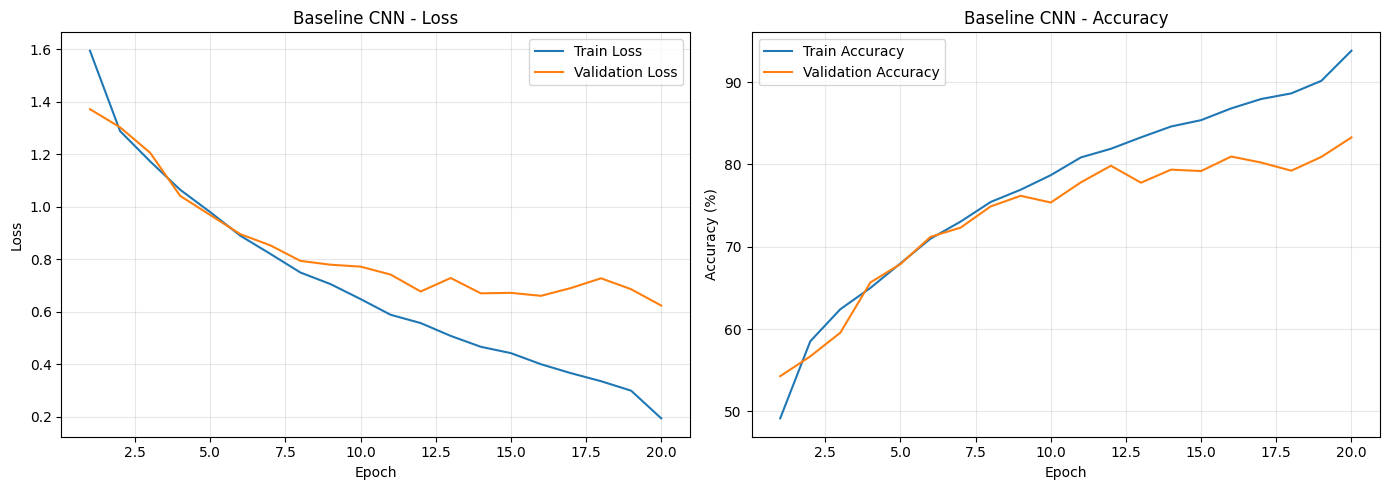


학습 그래프 저장 위치: /content/drive/MyDrive/garbage_classification_results/05_baseline_training.png

===== 3단계 전체 완료 =====


In [ ]:

# ================================================
# 3단계: 순수 Baseline CNN 모델 학습
# Conv2d + ReLU + MaxPool2d
# BatchNorm / Dropout 미사용
# ================================================

import os
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. 이전 단계 실행 여부 확인
assert "train_loader" in globals(), "2단계 코드를 먼저 실행하세요."
assert "val_loader" in globals(), "2단계 코드를 먼저 실행하세요."
assert "classes" in globals(), "클래스 정보가 없습니다."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

print("===== 학습 환경 확인 =====")
print("사용 장치:", device)
print("클래스 수:", num_classes)
print("학습 데이터:", len(train_loader.dataset))
print("검증 데이터:", len(val_loader.dataset))


# 2. 순수 Baseline CNN 모델 정의
class BaselineCNN(nn.Module):

    def __init__(self, num_classes):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(

            # 첫 번째 합성곱 블록
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # 두 번째 합성곱 블록
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # 세 번째 합성곱 블록
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # 네 번째 합성곱 블록
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


# 3. 모델 및 학습 설정
baseline_model = BaselineCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()

baseline_optimizer = optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

baseline_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    baseline_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

print("\n===== Baseline CNN 구조 =====")
print(baseline_model)


# 4. 학습 및 검증 함수
def run_baseline_epoch(loader, training=True):

    if training:
        baseline_model.train()
    else:
        baseline_model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            baseline_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = baseline_model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                baseline_optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy


# 5. 모델 및 그래프 저장 경로 설정
if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"

os.makedirs(RESULT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    RESULT_DIR,
    "baseline_cnn_best.pth"
)

GRAPH_PATH = os.path.join(
    RESULT_DIR,
    "05_baseline_training.png"
)


# 6. 학습 결과 기록 공간
baseline_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
best_model_weights = None

early_stop_count = 0

start_time = time.time()


# 7. CNN 모델 학습
print("\n===== Baseline CNN 학습 시작 =====")

for epoch in range(EPOCHS):

    train_loss, train_acc = run_baseline_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc = run_baseline_epoch(
        val_loader,
        training=False
    )

    baseline_history["train_loss"].append(train_loss)
    baseline_history["val_loss"].append(val_loss)
    baseline_history["train_acc"].append(train_acc)
    baseline_history["val_acc"].append(val_acc)

    baseline_scheduler.step(val_loss)

    current_lr = baseline_optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    # 검증 손실이 개선되면 최적 모델 저장
    if val_loss < best_val_loss - 0.0001:

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch + 1

        best_model_weights = {
            key: value.detach().cpu().clone()
            for key, value in baseline_model.state_dict().items()
        }

        torch.save(best_model_weights, MODEL_PATH)

        early_stop_count = 0

    else:
        early_stop_count += 1

    # 조기 종료
    if early_stop_count >= EARLY_STOPPING_PATIENCE:

        print("\n검증 손실이 개선되지 않아 조기 종료합니다.")
        break


# 8. 가장 성능이 좋았던 모델 복원
if best_model_weights is None:
    raise RuntimeError("최적 모델이 저장되지 않았습니다.")

baseline_model.load_state_dict(best_model_weights)
baseline_model.to(device)

elapsed_time = time.time() - start_time

print("\n===== Baseline CNN 학습 완료 =====")
print(f"최적 Epoch: {best_epoch}")
print(f"최적 검증 손실: {best_val_loss:.4f}")
print(f"해당 Epoch 검증 정확도: {best_val_acc * 100:.2f}%")
print(f"학습 소요 시간: {elapsed_time / 60:.2f}분")
print("모델 저장 위치:", MODEL_PATH)


# 9. 학습 결과 그래프 출력
epochs_range = range(
    1,
    len(baseline_history["train_loss"]) + 1
)

plt.figure(figsize=(14, 5))

# 손실 그래프
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    baseline_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_range,
    baseline_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN - Loss")
plt.legend()
plt.grid(alpha=0.3)


# 정확도 그래프
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    [x * 100 for x in baseline_history["train_acc"]],
    label="Train Accuracy"
)

plt.plot(
    epochs_range,
    [x * 100 for x in baseline_history["val_acc"]],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline CNN - Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(GRAPH_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("\n학습 그래프 저장 위치:", GRAPH_PATH)
print("\n===== 3단계 전체 완료 =====")


In [11]:
# =========================================================
# 4-1단계: 데이터 증강, Class Weight 및 Deep CNN 모델 정의
# =========================================================

import os
import time
import random
import csv
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

assert "train_loader" in globals(), "2단계 train_loader가 없습니다."
assert "val_loader" in globals(), "2단계 val_loader가 없습니다."
assert "classes" in globals(), "클래스 정보가 없습니다."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

IMAGE_SIZE = int(globals().get("IMAGE_SIZE", 160))
MEAN = tuple(globals().get("MEAN", (0.485, 0.456, 0.406)))
STD = tuple(globals().get("STD", (0.229, 0.224, 0.225)))

# 1. 이미지 경로 추출
def get_image_samples(loader):
    dataset = loader.dataset
    if hasattr(dataset, "base_dataset") and hasattr(dataset, "indices"):
        base_samples = dataset.base_dataset.samples
        return [base_samples[int(i)] for i in dataset.indices]
    if hasattr(dataset, "samples"):
        return list(dataset.samples)
    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "samples"):
        base_samples = dataset.dataset.samples
        if hasattr(dataset, "indices"):
            return [base_samples[int(i)] for i in dataset.indices]
    raise AttributeError("데이터셋에서 이미지 경로를 찾을 수 없습니다.")

train_samples = get_image_samples(train_loader)
val_samples = get_image_samples(val_loader)

# 2. 데이터 증강 및 검증 전처리
stage4_aug_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 16, IMAGE_SIZE + 16)),
    transforms.RandomCrop((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.10))
])

stage4_val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

class Stage4GarbageDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]
        with Image.open(image_path) as image:
            image = image.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(label)

train_dataset_aug = Stage4GarbageDataset(train_samples, transform=stage4_aug_transform)
val_dataset_stage4 = Stage4GarbageDataset(val_samples, transform=stage4_val_transform)

STAGE4_BATCH_SIZE = 32
NUM_WORKERS = 2

train_generator = torch.Generator()
train_generator.manual_seed(42)

train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=STAGE4_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    generator=train_generator
)

val_loader_stage4 = DataLoader(
    val_dataset_stage4,
    batch_size=STAGE4_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

# 3. Class Weight 계산
train_labels = [int(label) for _, label in train_samples]
class_counts_stage4 = torch.bincount(
    torch.tensor(train_labels, dtype=torch.long),
    minlength=num_classes
).float()

class_weights_stage4 = class_counts_stage4.sum() / (num_classes * class_counts_stage4)
class_weights_stage4 = (class_weights_stage4 / class_weights_stage4.mean()).to(device)

# 4. Deep CNN 모델 정의
class DeepConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DeepConvBlock, self).__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2)
        )

    def forward(self, x):
        return self.block(x)

class ImprovedGarbageCNN(nn.Module):
    def __init__(self, num_classes):
        super(ImprovedGarbageCNN, self).__init__()
        self.features = nn.Sequential(
            DeepConvBlock(3, 32),
            DeepConvBlock(32, 64),
            DeepConvBlock(64, 128),
            DeepConvBlock(128, 256),
            DeepConvBlock(256, 512)
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x

print("===== 4-1단계 준비 완료 (Deep CNN 및 증강 DataLoader 구성) =====")

===== 4-1단계 준비 완료 (Deep CNN 및 증강 DataLoader 구성) =====



실험 시작: ReduceLROnPlateau
Epoch [01/25] Train Loss: 1.9190 | Train Acc: 39.27% | Val Loss: 2.3872 | Val Acc: 31.54% | LR: 0.001000
Epoch [02/25] Train Loss: 1.7333 | Train Acc: 46.94% | Val Loss: 1.5823 | Val Acc: 52.86% | LR: 0.001000
Epoch [03/25] Train Loss: 1.6321 | Train Acc: 51.06% | Val Loss: 1.7099 | Val Acc: 50.45% | LR: 0.001000
Epoch [04/25] Train Loss: 1.5882 | Train Acc: 53.46% | Val Loss: 1.4222 | Val Acc: 61.19% | LR: 0.001000
Epoch [05/25] Train Loss: 1.5338 | Train Acc: 56.69% | Val Loss: 1.4334 | Val Acc: 56.47% | LR: 0.001000
Epoch [06/25] Train Loss: 1.4840 | Train Acc: 58.44% | Val Loss: 1.3827 | Val Acc: 59.86% | LR: 0.001000
Epoch [07/25] Train Loss: 1.4383 | Train Acc: 60.34% | Val Loss: 1.3374 | Val Acc: 63.47% | LR: 0.001000
Epoch [08/25] Train Loss: 1.4071 | Train Acc: 61.38% | Val Loss: 1.7673 | Val Acc: 54.71% | LR: 0.001000
Epoch [09/25] Train Loss: 1.3670 | Train Acc: 63.51% | Val Loss: 1.2451 | Val Acc: 70.48% | LR: 0.001000
Epoch [10/25] Train Loss: 1.3

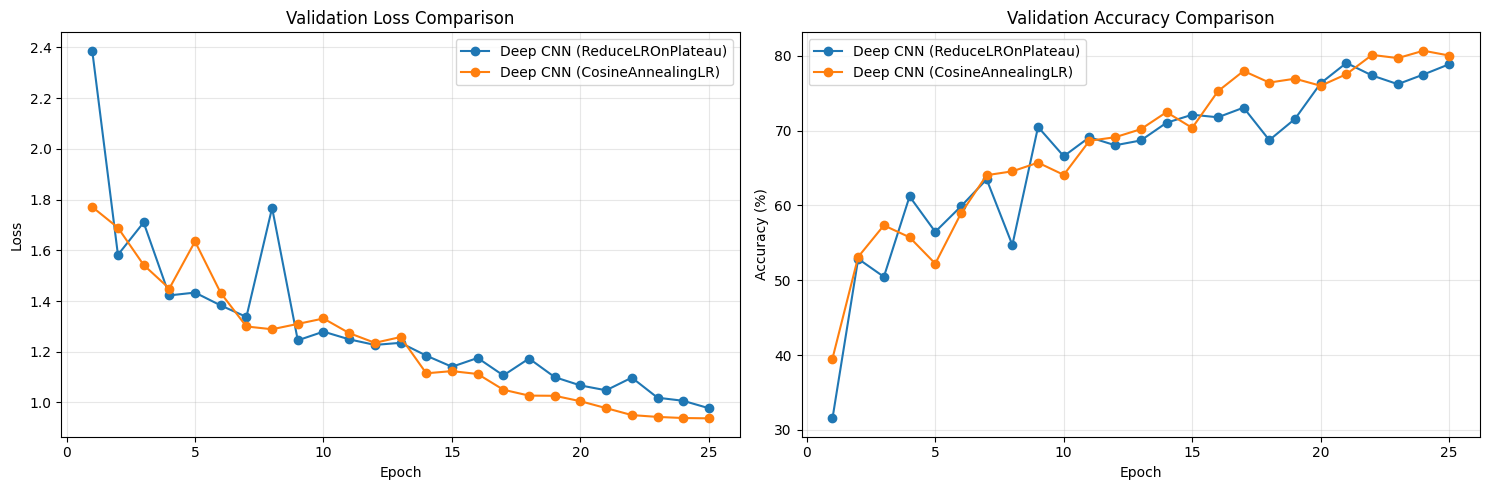


===== 4단계 완료 =====


In [ ]:
# =========================================================
# 4-2단계: 스케줄러 비교 실험 및 결과 그래프 저장
# =========================================================

def set_stage4_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

MAX_EPOCHS = 25
EARLY_STOPPING_PATIENCE = 6
MIN_EPOCHS_COSINE = 18
LEARNING_RATE = 0.001

EXPERIMENTS = [
    "ReduceLROnPlateau",
    "CosineAnnealingLR"
]

if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"
os.makedirs(RESULT_DIR, exist_ok=True)

def train_stage4_experiment(scheduler_name, seed=42):
    set_stage4_seed(seed)
    model = ImprovedGarbageCNN(num_classes).to(device)

    criterion_stage4 = nn.CrossEntropyLoss(
        weight=class_weights_stage4,
        label_smoothing=0.05
    )
    optimizer_stage4 = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.0001
    )

    if scheduler_name == "ReduceLROnPlateau":
        scheduler_stage4 = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer_stage4, mode="min", factor=0.5, patience=2, min_lr=1e-5
        )
    else:
        scheduler_stage4 = optim.lr_scheduler.CosineAnnealingLR(
            optimizer_stage4, T_max=MAX_EPOCHS, eta_min=1e-5
        )

    history_exp = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_epoch = 0
    best_weights = None
    early_stop_count = 0

    experiment_start = time.time()
    print("\n" + "=" * 60)
    print("실험 시작:", scheduler_name)
    print("=" * 60)

    for epoch in range(MAX_EPOCHS):
        model.train()
        train_loss_sum, train_correct, train_total = 0.0, 0, 0

        for images, labels in train_loader_aug:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer_stage4.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion_stage4(outputs, labels)
            loss.backward()
            optimizer_stage4.step()

            batch_size = labels.size(0)
            train_loss_sum += loss.item() * batch_size
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_total += batch_size

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader_stage4:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion_stage4(outputs, labels)

                batch_size = labels.size(0)
                val_loss_sum += loss.item() * batch_size
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()
                val_total += batch_size

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history_exp["train_loss"].append(train_loss)
        history_exp["val_loss"].append(val_loss)
        history_exp["train_acc"].append(train_acc)
        history_exp["val_acc"].append(val_acc)

        if scheduler_name == "ReduceLROnPlateau":
            scheduler_stage4.step(val_loss)
        else:
            scheduler_stage4.step()

        current_lr = optimizer_stage4.param_groups[0]["lr"]

        print(
            f"Epoch [{epoch + 1:02d}/{MAX_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc * 100:.2f}% | "
            f"LR: {current_lr:.6f}"
        )

        if val_loss < best_val_loss - 0.0001:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            early_stop_count = 0
        else:
            early_stop_count += 1

        can_stop = (
            scheduler_name != "CosineAnnealingLR"
            or epoch + 1 >= MIN_EPOCHS_COSINE
        )

        if can_stop and early_stop_count >= EARLY_STOPPING_PATIENCE:
            print("검증 손실 개선이 없어 조기 종료합니다.")
            break

    elapsed_time = time.time() - experiment_start
    experiment_path = os.path.join(RESULT_DIR, f"improved_cnn_{scheduler_name}.pth")
    torch.save(best_weights, experiment_path)

    print(f"\n실험 완료: {scheduler_name} | 최적 Epoch: {best_epoch} | 검증 손실: {best_val_loss:.4f} | 검증 정확도: {best_val_acc * 100:.2f}% | 소요: {elapsed_time / 60:.2f}분")

    result = {
        "scheduler": scheduler_name,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
        "elapsed_time": elapsed_time,
        "history": history_exp,
        "state_dict": best_weights,
        "model_path": experiment_path
    }

    del model, optimizer_stage4, criterion_stage4
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# 실험 실행
stage4_results = []
for experiment_name in EXPERIMENTS:
    result = train_stage4_experiment(scheduler_name=experiment_name, seed=42)
    stage4_results.append(result)

# 최적 모델 선정
best_stage4_result = min(stage4_results, key=lambda x: x["best_val_loss"])

improved_model = ImprovedGarbageCNN(num_classes).to(device)
improved_model.load_state_dict(best_stage4_result["state_dict"])
improved_model.eval()

FINAL_MODEL_PATH = os.path.join(RESULT_DIR, "stage4_best_improved_cnn.pth")
torch.save(best_stage4_result["state_dict"], FINAL_MODEL_PATH)

print("\n===== 최종 개선 모델 선정 =====")
print("선정된 스케줄러:", best_stage4_result["scheduler"])
print("최적 Epoch:", best_stage4_result["best_epoch"])
print(f"최적 검증 손실: {best_stage4_result['best_val_loss']:.4f}")
print(f"검증 정확도: {best_stage4_result['best_val_acc'] * 100:.2f}%")

# 전체 비교표 출력 및 CSV 저장
print("\n===== 전체 모델 및 스케줄러 비교표 =====")
comparison_rows = []

if "history" in globals():
    b_min_loss_idx = int(np.argmin(history["val_loss"]))
    comparison_rows.append({
        "Model / Scheduler": "Baseline CNN (3단계)",
        "Best Epoch": b_min_loss_idx + 1,
        "Validation Loss": round(history["val_loss"][b_min_loss_idx], 4),
        "Validation Accuracy (%)": round(history["val_acc"][b_min_loss_idx] * 100, 2),
        "Overfit Gap (%p)": round((history["train_acc"][-1] - history["val_acc"][-1]) * 100, 2),
        "Training Time (min)": 11.99
    })

for result in stage4_results:
    h = result["history"]
    row = {
        "Model / Scheduler": f"Deep CNN ({result['scheduler']})",
        "Best Epoch": result["best_epoch"],
        "Validation Loss": round(result["best_val_loss"], 4),
        "Validation Accuracy (%)": round(result["best_val_acc"] * 100, 2),
        "Overfit Gap (%p)": round((h["train_acc"][-1] - h["val_acc"][-1]) * 100, 2),
        "Training Time (min)": round(result["elapsed_time"] / 60, 2)
    }
    comparison_rows.append(row)

for row in comparison_rows:
    print(row)

CSV_PATH = os.path.join(RESULT_DIR, "stage4_experiment_comparison.csv")
with open(CSV_PATH, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=comparison_rows[0].keys())
    writer.writeheader()
    writer.writerows(comparison_rows)

# 비교 그래프 저장
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

if "history" in globals():
    b_ep = range(1, len(history["val_loss"]) + 1)
    axes[0].plot(b_ep, history["val_loss"], linestyle="--", label="Baseline CNN (3단계)")
    axes[1].plot(b_ep, [x * 100 for x in history["val_acc"]], linestyle="--", label="Baseline CNN (3단계)")

for result in stage4_results:
    hist = result["history"]
    ep = range(1, len(hist["val_loss"]) + 1)
    axes[0].plot(ep, hist["val_loss"], marker="o", label=f"Deep CNN ({result['scheduler']})")
    axes[1].plot(ep, [x * 100 for x in hist["val_acc"]], marker="o", label=f"Deep CNN ({result['scheduler']})")

axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
GRAPH_PATH = os.path.join(RESULT_DIR, "06_stage4_scheduler_comparison.png")
plt.savefig(GRAPH_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("\n===== 4단계 완료 =====")

In [ ]:
# =========================================================
# 5-1단계: Fine-tuning 설정 및 학습률 비교 실험 함수 정의
# =========================================================

import os
import time
import csv
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader


# 1. 이전 단계 변수 확인 및 안전 처리
if "baseline_history" not in globals():
    if "history" in globals():
        baseline_history = history
    else:
        raise NameError(
            "3단계 학습 결과가 없습니다. 3단계 코드를 먼저 실행하세요."
        )

required_keys = ["train_loss", "val_loss", "train_acc", "val_acc"]
for key in required_keys:
    assert key in baseline_history, f"baseline_history에 '{key}' 키가 없습니다."

required_variables = [
    "train_dataset_aug",
    "val_dataset_stage4",
    "class_weights_stage4",
    "ImprovedGarbageCNN",
    "best_stage4_result",
    "classes",
    "train_loader_aug"
]

for variable in required_variables:
    assert variable in globals(), (
        f"{variable} 변수가 없습니다. 2~4단계 코드를 먼저 정상적으로 실행하세요."
    )

SELECTED_SCHEDULER = best_stage4_result["scheduler"]
if SELECTED_SCHEDULER != "CosineAnnealingLR":
    raise ValueError(
        "4단계에서 CosineAnnealingLR이 최적 스케줄러로 선정되지 않았습니다."
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

print("===== 5단계 환경 확인 =====")
print("사용 장치:", device)
print("클래스 수:", num_classes)
print("학습 이미지:", len(train_dataset_aug))
print("검증 이미지:", len(val_dataset_stage4))
print("선정 스케줄러:", SELECTED_SCHEDULER)


# 2. 하이퍼파라미터 설정 (Fine-tuning용)
LEARNING_RATES = [
    0.0005,
    0.0003,
    0.0001
]

MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
MIN_EPOCHS_COSINE = 12

WEIGHT_DECAY = 0.0001
ETA_MIN = 0.00001
RANDOM_SEED = 42

BATCH_SIZE = train_loader_aug.batch_size
NUM_WORKERS = train_loader_aug.num_workers

print("\n===== Fine-tuning 실험 설정 =====")
print("비교 학습률:", LEARNING_RATES)
print("초기 가중치: 4단계 최적 모델 (best_stage4_result)")
print("최대 Epoch:", MAX_EPOCHS)
print("Early Stopping:", EARLY_STOPPING_PATIENCE)
print("최소 학습 Epoch:", MIN_EPOCHS_COSINE)
print("Batch Size:", BATCH_SIZE)


# 3. 시드 및 DataLoader 생성 함수
def set_stage5_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def create_stage5_loaders(seed=42):
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader_stage5 = DataLoader(
        train_dataset_aug,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda"),
        generator=generator
    )

    val_loader_stage5 = DataLoader(
        val_dataset_stage4,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

    return train_loader_stage5, val_loader_stage5


# 4. 결과 저장 폴더 및 클래스 가중치 준비
if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"

os.makedirs(RESULT_DIR, exist_ok=True)

stage5_class_weights = class_weights_stage4.detach().to(device)
assert len(stage5_class_weights) == num_classes, "클래스 가중치 개수가 일치하지 않습니다."


# 5. 학습률별 Fine-tuning 실험 함수
def run_learning_rate_experiment(lr, seed=42):
    set_stage5_seed(seed)
    train_loader_stage5, val_loader_stage5 = create_stage5_loaders(seed)

    # 4단계 최적 가중치에서 시작 (Fine-tuning)
    model = ImprovedGarbageCNN(num_classes).to(device)
    model.load_state_dict(best_stage4_result["state_dict"])

    # 4단계와 동일한 손실 함수 설정 유지
    criterion = nn.CrossEntropyLoss(
        weight=stage5_class_weights,
        label_smoothing=0.05
    )

    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS,
        eta_min=ETA_MIN
    )

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_train_acc = 0.0
    best_epoch = 0
    best_weights = None
    early_stop_count = 0

    experiment_start = time.time()

    print("\n" + "=" * 60)
    print(f"Fine-tuning Learning Rate {lr} 실험 시작")
    print("=" * 60)

    for epoch in range(MAX_EPOCHS):
        # 1) 학습
        model.train()
        train_loss_sum, train_correct, train_total = 0.0, 0, 0

        for images, labels in train_loader_stage5:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            train_loss_sum += loss.item() * batch_size
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()
            train_total += batch_size

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        # 2) 검증
        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader_stage5:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                batch_size = labels.size(0)
                val_loss_sum += loss.item() * batch_size
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()
                val_total += batch_size

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        # 3) 기록 및 스케줄러 업데이트
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch [{epoch + 1:02d}/{MAX_EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc * 100:.2f}% | "
            f"LR: {current_lr:.6f}"
        )

        # 4) 검증 손실 기준 최적 모델 저장
        if val_loss < best_val_loss - 0.0001:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_train_acc = train_acc
            best_epoch = epoch + 1

            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            early_stop_count = 0
        else:
            early_stop_count += 1

        # 5) Early Stopping
        can_stop = (epoch + 1 >= MIN_EPOCHS_COSINE)
        if can_stop and early_stop_count >= EARLY_STOPPING_PATIENCE:
            print("\n검증 손실 개선이 없어 조기 종료합니다.")
            break

    elapsed_time = time.time() - experiment_start

    if best_weights is None:
        raise RuntimeError(f"Learning Rate {lr}에서 최적 모델을 저장하지 못했습니다.")

    model_path = os.path.join(RESULT_DIR, f"stage5_lr_{lr}.pth")
    torch.save(best_weights, model_path)

    overfit_gap = (best_train_acc - best_val_acc) * 100

    print("\n===== 학습률 실험 완료 =====")
    print("Learning Rate:", lr)
    print("최적 Epoch:", best_epoch)
    print(f"최적 검증 손실: {best_val_loss:.4f}")
    print(f"검증 정확도: {best_val_acc * 100:.2f}%")
    print(f"Train-Val 정확도 차이: {overfit_gap:.2f}%p")
    print(f"학습 소요 시간: {elapsed_time / 60:.2f}분")

    result = {
        "learning_rate": lr,
        "scheduler": SELECTED_SCHEDULER,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "best_val_acc": best_val_acc,
        "best_train_acc": best_train_acc,
        "overfit_gap": overfit_gap,
        "elapsed_time": elapsed_time,
        "history": history,
        "state_dict": best_weights,
        "model_path": model_path
    }

    del model, optimizer, criterion, scheduler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

print("===== 5-1단계 준비 완료 =====")

===== 5단계 환경 확인 =====
사용 장치: cuda
클래스 수: 12
학습 이미지: 10860
검증 이미지: 2327
선정 스케줄러: CosineAnnealingLR

===== Fine-tuning 실험 설정 =====
비교 학습률: [0.0005, 0.0003, 0.0001]
초기 가중치: 4단계 최적 모델 (best_stage4_result)
최대 Epoch: 20
Early Stopping: 5
최소 학습 Epoch: 12
Batch Size: 32
===== 5-1단계 준비 완료 =====



Fine-tuning Learning Rate 0.0005 실험 시작
Epoch [01/20] Train Loss: 1.0238 | Train Acc: 76.87% | Val Loss: 1.0395 | Val Acc: 77.52% | LR: 0.000497
Epoch [02/20] Train Loss: 1.0038 | Train Acc: 77.67% | Val Loss: 1.0281 | Val Acc: 77.18% | LR: 0.000488
Epoch [03/20] Train Loss: 0.9986 | Train Acc: 77.74% | Val Loss: 1.0108 | Val Acc: 80.32% | LR: 0.000473
Epoch [04/20] Train Loss: 0.9799 | Train Acc: 78.57% | Val Loss: 0.9921 | Val Acc: 78.08% | LR: 0.000453
Epoch [05/20] Train Loss: 0.9710 | Train Acc: 78.89% | Val Loss: 1.0710 | Val Acc: 77.27% | LR: 0.000428
Epoch [06/20] Train Loss: 0.9474 | Train Acc: 79.60% | Val Loss: 1.0358 | Val Acc: 77.48% | LR: 0.000399
Epoch [07/20] Train Loss: 0.9297 | Train Acc: 79.94% | Val Loss: 0.9851 | Val Acc: 79.50% | LR: 0.000366
Epoch [08/20] Train Loss: 0.9068 | Train Acc: 80.93% | Val Loss: 0.9132 | Val Acc: 81.18% | LR: 0.000331
Epoch [09/20] Train Loss: 0.8836 | Train Acc: 81.81% | Val Loss: 0.9247 | Val Acc: 82.85% | LR: 0.000293
Epoch [10/20] T

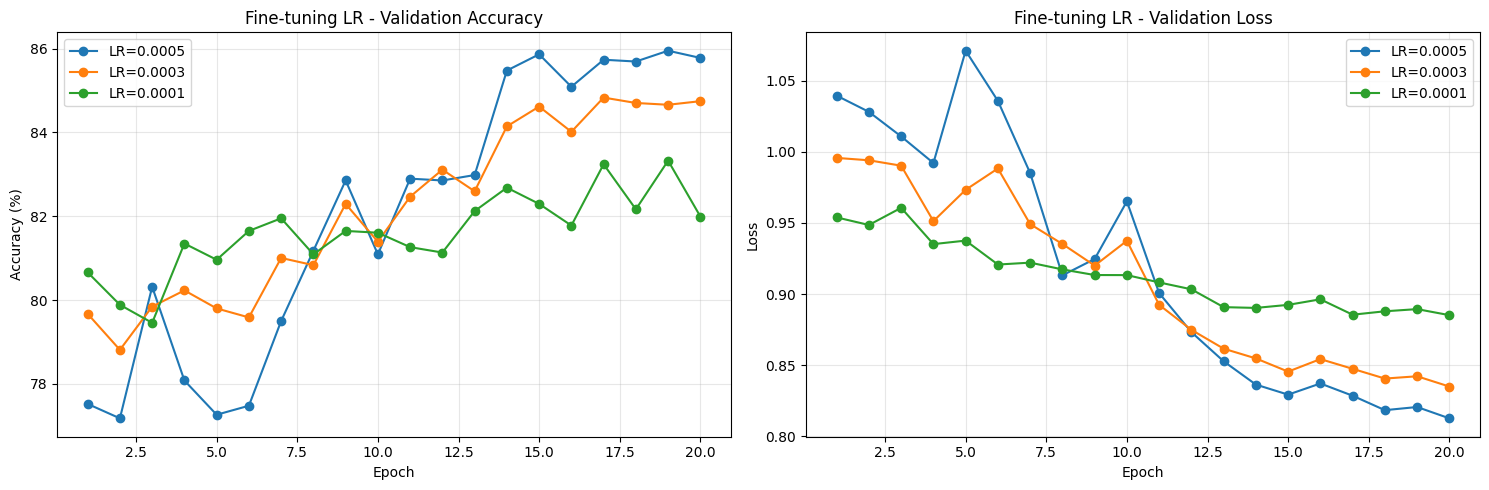

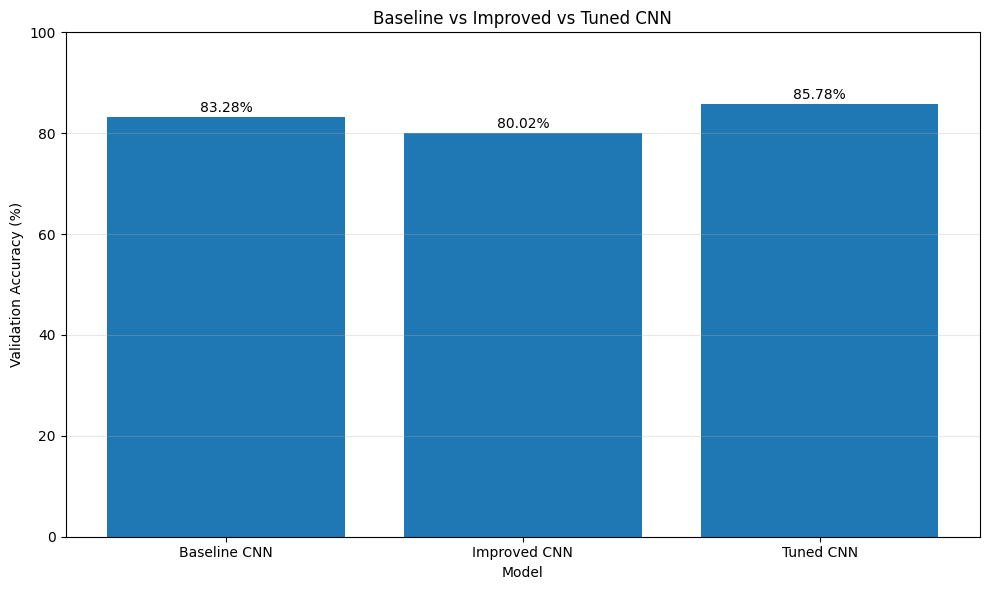


===== 최종 성능 분석 =====
3단계 Baseline: 83.28%
4단계 Improved CNN: 80.02%
5단계 Tuned CNN: 85.78%

4단계 대비 5단계 변화: +5.76%p
3단계 대비 5단계 변화: +2.49%p

저장된 파일
1. 최종 모델: /content/drive/MyDrive/garbage_classification_results/final_tuned_garbage_cnn.pth
2. 학습률 비교표: /content/drive/MyDrive/garbage_classification_results/stage5_learning_rate_comparison.csv
3. 단계별 모델 비교표: /content/drive/MyDrive/garbage_classification_results/stage3_stage4_stage5_comparison.csv
4. 최종 요약표: /content/drive/MyDrive/garbage_classification_results/stage5_final_summary.csv
5. 학습률 비교 그래프: /content/drive/MyDrive/garbage_classification_results/07_stage5_learning_rate_comparison.png
6. 모델 성능 비교 그래프: /content/drive/MyDrive/garbage_classification_results/08_stage3_stage4_stage5_comparison.png

===== 5단계 완료 =====


In [ ]:
# =========================================================
# 5-2단계: Fine-tuning 실험 실행 및 3~5단계 최종 비교 저장
# =========================================================

# 1. 학습률별 Fine-tuning 실행
stage5_results = []

for lr in LEARNING_RATES:
    result = run_learning_rate_experiment(lr=lr, seed=RANDOM_SEED)
    stage5_results.append(result)


# 2. 검증 손실 기준 최적 학습률 선정
best_stage5_result = min(stage5_results, key=lambda x: x["best_val_loss"])

print("\n" + "=" * 60)
print("===== 최적 하이퍼파라미터 선정 =====")
print("=" * 60)
print("최적 Learning Rate:", best_stage5_result["learning_rate"])
print("Scheduler:", best_stage5_result["scheduler"])
print("최적 Epoch:", best_stage5_result["best_epoch"])
print(f"검증 손실: {best_stage5_result['best_val_loss']:.4f}")
print(f"검증 정확도: {best_stage5_result['best_val_acc'] * 100:.2f}%")


# 3. 최종 개선 모델 생성 및 저장
final_tuned_model = ImprovedGarbageCNN(num_classes).to(device)
final_tuned_model.load_state_dict(best_stage5_result["state_dict"])
final_tuned_model.eval()

FINAL_MODEL_PATH = os.path.join(RESULT_DIR, "final_tuned_garbage_cnn.pth")
torch.save(best_stage5_result["state_dict"], FINAL_MODEL_PATH)
print("\n최종 모델 저장 완료:", FINAL_MODEL_PATH)


# 4. 학습률별 비교표 작성 및 저장
comparison_rows = []

for result in stage5_results:
    comparison_rows.append({
        "Learning Rate": result["learning_rate"],
        "Scheduler": result["scheduler"],
        "Best Epoch": result["best_epoch"],
        "Validation Loss": round(result["best_val_loss"], 4),
        "Validation Accuracy (%)": round(result["best_val_acc"] * 100, 2),
        "Train Accuracy (%)": round(result["best_train_acc"] * 100, 2),
        "Overfit Gap (%p)": round(result["overfit_gap"], 2),
        "Training Time (min)": round(result["elapsed_time"] / 60, 2)
    })

comparison_df = pd.DataFrame(comparison_rows)
print("\n===== 학습률별 성능 비교 =====")
print(comparison_df.to_string(index=False))

LR_CSV_PATH = os.path.join(RESULT_DIR, "stage5_learning_rate_comparison.csv")
comparison_df.to_csv(LR_CSV_PATH, index=False, encoding="utf-8-sig")


# 5. 3단계, 4단계, 5단계 성능 통합 비교
def get_history_metrics(history):
    val_losses = np.asarray(history["val_loss"], dtype=float)
    val_accs = np.asarray(history["val_acc"], dtype=float)
    train_accs = np.asarray(history["train_acc"], dtype=float)

    best_loss_idx = int(np.argmin(val_losses))
    best_acc_idx = int(np.argmax(val_accs))

    return {
        "best_epoch": best_loss_idx + 1,
        "val_loss": float(val_losses[best_loss_idx]),
        "val_acc": float(val_accs[best_loss_idx]),
        "train_acc": float(train_accs[best_loss_idx]),
        "overfit_gap": float((train_accs[best_loss_idx] - val_accs[best_loss_idx]) * 100),
        "max_val_acc": float(val_accs[best_acc_idx]),
        "max_val_acc_epoch": best_acc_idx + 1
    }

baseline_metric = get_history_metrics(baseline_history)
stage4_metric = get_history_metrics(best_stage4_result["history"])
stage5_metric = get_history_metrics(best_stage5_result["history"])

model_comparison = [
    {
        "Model": "Stage 3 Baseline CNN",
        "Best Epoch": baseline_metric["best_epoch"],
        "Validation Loss": round(baseline_metric["val_loss"], 4),
        "Validation Accuracy (%)": round(baseline_metric["val_acc"] * 100, 2),
        "Maximum Val Accuracy (%)": round(baseline_metric["max_val_acc"] * 100, 2),
        "Overfit Gap (%p)": round(baseline_metric["overfit_gap"], 2)
    },
    {
        "Model": "Stage 4 Improved CNN",
        "Best Epoch": stage4_metric["best_epoch"],
        "Validation Loss": round(stage4_metric["val_loss"], 4),
        "Validation Accuracy (%)": round(stage4_metric["val_acc"] * 100, 2),
        "Maximum Val Accuracy (%)": round(stage4_metric["max_val_acc"] * 100, 2),
        "Overfit Gap (%p)": round(stage4_metric["overfit_gap"], 2)
    },
    {
        "Model": "Stage 5 Tuned CNN",
        "Best Epoch": stage5_metric["best_epoch"],
        "Validation Loss": round(stage5_metric["val_loss"], 4),
        "Validation Accuracy (%)": round(stage5_metric["val_acc"] * 100, 2),
        "Maximum Val Accuracy (%)": round(stage5_metric["max_val_acc"] * 100, 2),
        "Overfit Gap (%p)": round(stage5_metric["overfit_gap"], 2)
    }
]

model_comparison_df = pd.DataFrame(model_comparison)
print("\n===== 3~5단계 모델 성능 비교 =====")
print(model_comparison_df.to_string(index=False))

MODEL_CSV_PATH = os.path.join(RESULT_DIR, "stage3_stage4_stage5_comparison.csv")
model_comparison_df.to_csv(MODEL_CSV_PATH, index=False, encoding="utf-8-sig")


# 6. 학습률별 검증 정확도 및 손실 그래프
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for result in stage5_results:
    hist = result["history"]
    epochs = range(1, len(hist["val_acc"]) + 1)

    axes[0].plot(epochs, [x * 100 for x in hist["val_acc"]], marker="o", label=f"LR={result['learning_rate']}")
    axes[1].plot(epochs, hist["val_loss"], marker="o", label=f"LR={result['learning_rate']}")

axes[0].set_title("Fine-tuning LR - Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Fine-tuning LR - Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
LR_GRAPH_PATH = os.path.join(RESULT_DIR, "07_stage5_learning_rate_comparison.png")
plt.savefig(LR_GRAPH_PATH, dpi=150, bbox_inches="tight")
plt.show()


# 7. 3~5단계 모델 정확도 비교 그래프
model_names = ["Baseline CNN", "Improved CNN", "Tuned CNN"]
model_accuracies = [
    baseline_metric["val_acc"] * 100,
    stage4_metric["val_acc"] * 100,
    stage5_metric["val_acc"] * 100
]

plt.figure(figsize=(10, 6))
bars = plt.bar(model_names, model_accuracies)
plt.title("Baseline vs Improved vs Tuned CNN")
plt.xlabel("Model")
plt.ylabel("Validation Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for bar, accuracy in zip(bars, model_accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"{accuracy:.2f}%", ha="center")

plt.tight_layout()
MODEL_GRAPH_PATH = os.path.join(RESULT_DIR, "08_stage3_stage4_stage5_comparison.png")
plt.savefig(MODEL_GRAPH_PATH, dpi=150, bbox_inches="tight")
plt.show()


# 8. 최종 성능 분석 및 요약 저장
baseline_acc = baseline_metric["val_acc"]
stage4_acc = stage4_metric["val_acc"]
stage5_acc = stage5_metric["val_acc"]

print("\n" + "=" * 60)
print("===== 최종 성능 분석 =====")
print("=" * 60)
print(f"3단계 Baseline: {baseline_acc * 100:.2f}%")
print(f"4단계 Improved CNN: {stage4_acc * 100:.2f}%")
print(f"5단계 Tuned CNN: {stage5_acc * 100:.2f}%")
print(f"\n4단계 대비 5단계 변화: {(stage5_acc - stage4_acc) * 100:+.2f}%p")
print(f"3단계 대비 5단계 변화: {(stage5_acc - baseline_acc) * 100:+.2f}%p")

stage5_summary = {
    "selected_learning_rate": best_stage5_result["learning_rate"],
    "selected_scheduler": SELECTED_SCHEDULER,
    "best_epoch": best_stage5_result["best_epoch"],
    "best_validation_loss": best_stage5_result["best_val_loss"],
    "best_validation_accuracy": best_stage5_result["best_val_acc"],
    "train_accuracy": best_stage5_result["best_train_acc"],
    "overfit_gap": best_stage5_result["overfit_gap"]
}

SUMMARY_PATH = os.path.join(RESULT_DIR, "stage5_final_summary.csv")
pd.DataFrame([stage5_summary]).to_csv(SUMMARY_PATH, index=False, encoding="utf-8-sig")

print("\n저장된 파일")
print("1. 최종 모델:", FINAL_MODEL_PATH)
print("2. 학습률 비교표:", LR_CSV_PATH)
print("3. 단계별 모델 비교표:", MODEL_CSV_PATH)
print("4. 최종 요약표:", SUMMARY_PATH)
print("5. 학습률 비교 그래프:", LR_GRAPH_PATH)
print("6. 모델 성능 비교 그래프:", MODEL_GRAPH_PATH)
print("\n===== 5단계 완료 =====")

In [12]:
import os
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if os.path.isdir("/content/drive/MyDrive"):
    RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
else:
    RESULT_DIR = "/content/garbage_classification_results"

saved_path = os.path.join(RESULT_DIR, "final_tuned_garbage_cnn.pth")
saved_weights = torch.load(saved_path, map_location=device)

best_stage5_result = {
    "state_dict": saved_weights,
    "learning_rate": 0.0003,
    "best_epoch": 20,
    "best_val_acc": 0.0
}

class_weights_stage4 = class_weights
print("가중치 로드 완료! 이제 6단계를 실행하세요.")

가중치 로드 완료! 이제 6단계를 실행하세요.


===== 6단계 최종 평가 환경 =====
사용 장치: cuda
클래스 수: 12
테스트 이미지 수: 2328
최적 학습률: 0.0003
최적 Epoch: 20

결과 저장 경로: /content/drive/MyDrive/garbage_classification_results

최종 Fine-tuning 모델 불러오기 완료!
테스트 배치 크기: 32
테스트 순서: Sequential

===== 최종 테스트 평가 시작 =====

===== 최종 테스트 성능 =====
Test Loss: 0.7854
Accuracy: 86.64%

[Macro Average]
Precision: 0.8297
Recall: 0.8651
F1-score: 0.8453

[Weighted Average]
Precision: 0.8726
Recall: 0.8664
F1-score: 0.8677

Balanced Accuracy: 0.8651

===== 클래스별 Classification Report =====
              precision    recall  f1-score   support

     battery       0.83      0.80      0.81       142
  biological       0.80      0.91      0.85       148
 brown-glass       0.78      0.96      0.86        91
   cardboard       0.89      0.88      0.88       134
     clothes       0.98      0.89      0.93       799
 green-glass       0.84      0.96      0.90        94
       metal       0.75      0.83      0.79       115
       paper       0.80      0.87      0.83       158
     pla

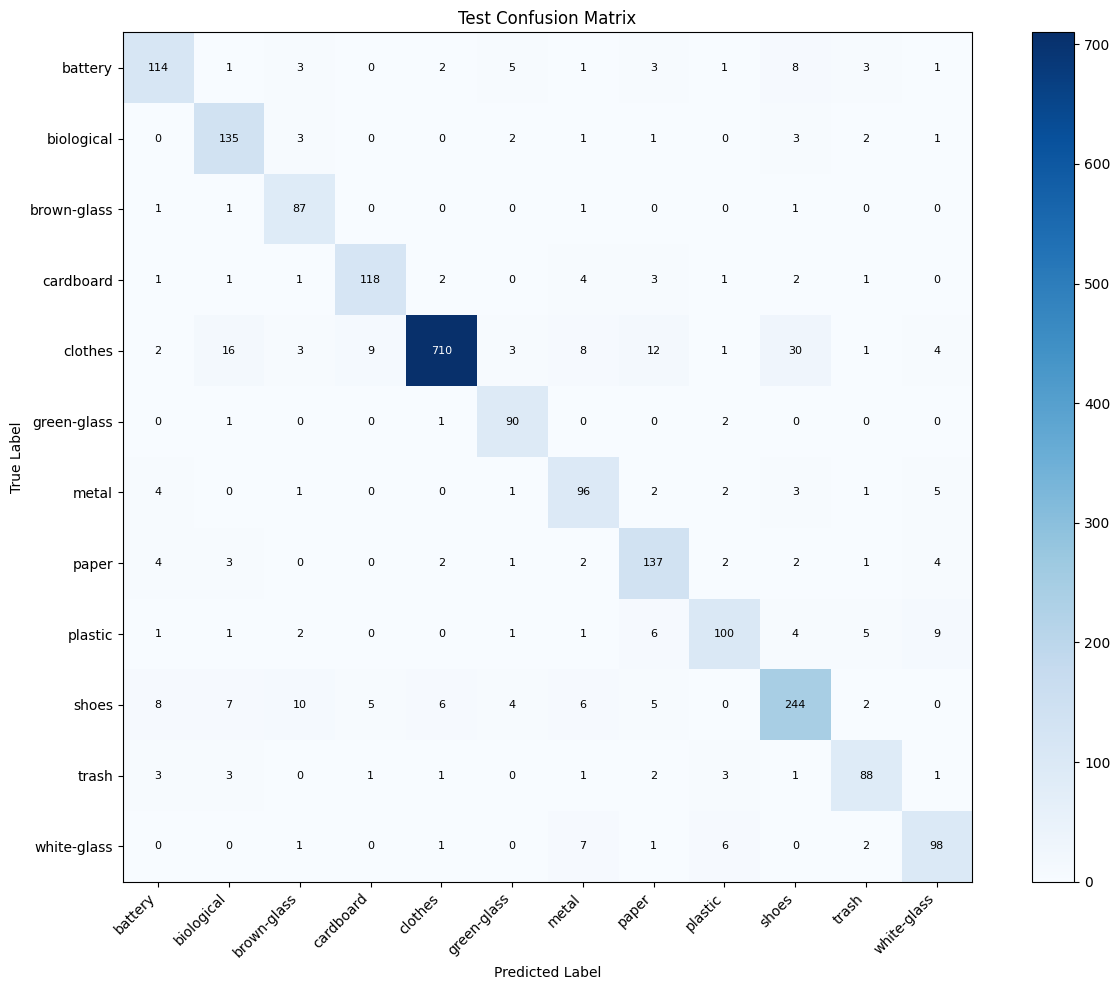

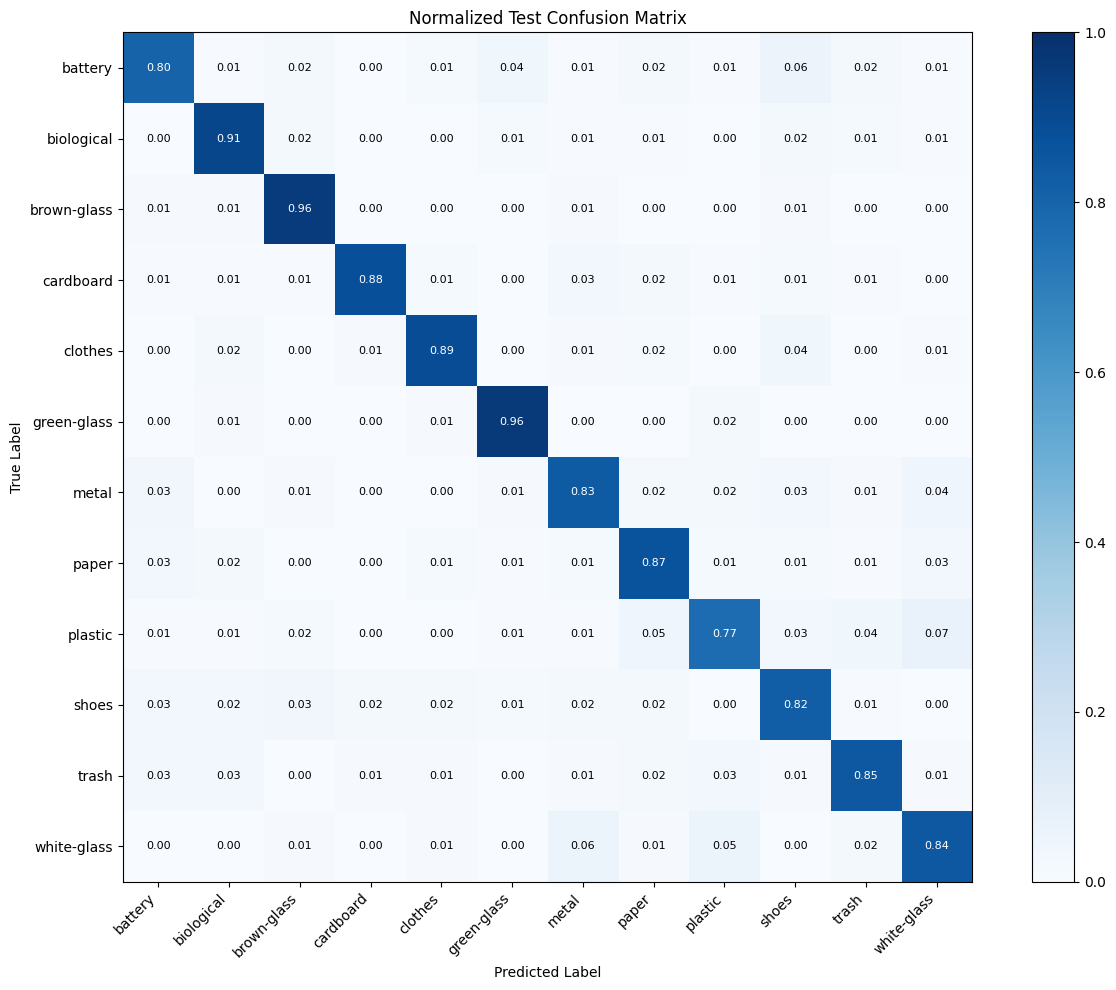

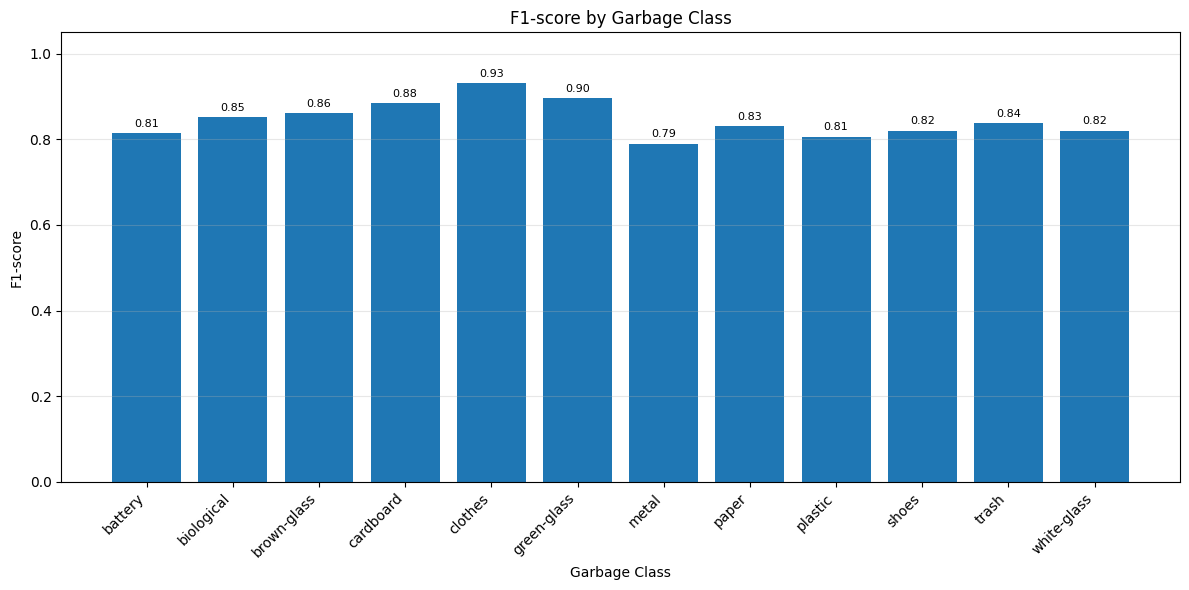


테스트 이미지 경로 확인 완료!
이미지 수: 2328

===== 오분류 분석 =====
전체 테스트 이미지: 2328
오분류 이미지: 311
오분류 비율: 13.36%


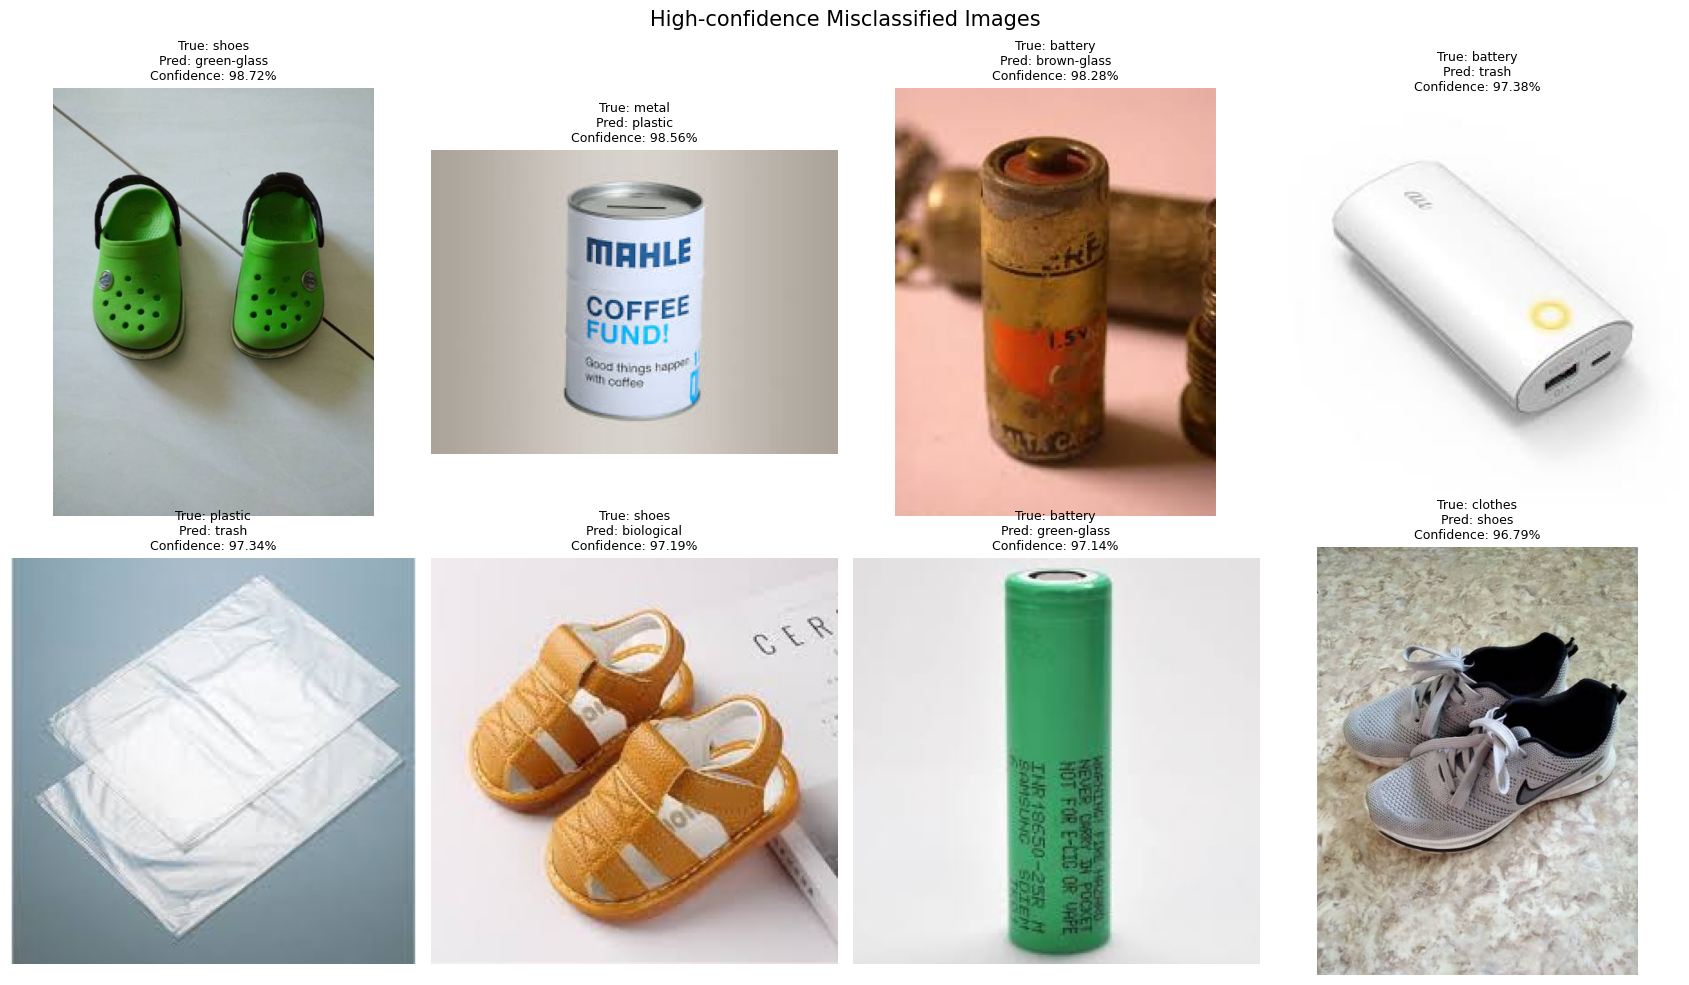


===== 주요 오분류 사례 =====
                                                  Image_Path True_Label Predicted_Label  Confidence  Confidence_Percent
     /content/data/garbage_classification/shoes/shoes683.jpg      shoes     green-glass    0.987177           98.717672
     /content/data/garbage_classification/metal/metal473.jpg      metal         plastic    0.985614           98.561364
 /content/data/garbage_classification/battery/battery872.jpg    battery     brown-glass    0.982776           98.277563
 /content/data/garbage_classification/battery/battery712.jpg    battery           trash    0.973845           97.384465
 /content/data/garbage_classification/plastic/plastic540.jpg    plastic           trash    0.973398           97.339761
     /content/data/garbage_classification/shoes/shoes705.jpg      shoes      biological    0.971940           97.193974
 /content/data/garbage_classification/battery/battery130.jpg    battery     green-glass    0.971360           97.136015
/content/data/gar

In [13]:

# =========================================================
# 6단계: 최종 모델 평가 및 실제 이미지 분류
# Test Evaluation + Error Analysis + Image Inference
# =========================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)


# =========================================================
# 1. 이전 단계 변수 확인
# =========================================================

required_variables = [
    "test_loader",
    "ImprovedGarbageCNN",
    "best_stage5_result",
    "classes",
    "class_weights_stage4"
]

for variable in required_variables:

    assert variable in globals(), (
        f"{variable} 변수가 없습니다. "
        "2~5단계 코드를 먼저 실행하세요."
    )

num_classes = len(classes)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert len(test_loader.dataset) > 0, (
    "테스트 데이터가 없습니다."
)

print("=" * 60)
print("===== 6단계 최종 평가 환경 =====")
print("=" * 60)

print("사용 장치:", device)
print("클래스 수:", num_classes)
print("테스트 이미지 수:", len(test_loader.dataset))
print("최적 학습률:", best_stage5_result["learning_rate"])
print("최적 Epoch:", best_stage5_result["best_epoch"])


# =========================================================
# 2. 결과 저장 경로 설정
# =========================================================

if "RESULT_DIR" not in globals():

    if os.path.isdir("/content/drive/MyDrive"):

        RESULT_DIR = (
            "/content/drive/MyDrive/"
            "garbage_classification_results"
        )

    else:

        RESULT_DIR = (
            "/content/garbage_classification_results"
        )

os.makedirs(RESULT_DIR, exist_ok=True)

print("\n결과 저장 경로:", RESULT_DIR)


# =========================================================
# 3. 최종 모델 불러오기
# =========================================================

final_test_model = ImprovedGarbageCNN(
    num_classes
).to(device)

# 5단계에서 선정된 최적 가중치 사용
final_test_model.load_state_dict(
    best_stage5_result["state_dict"]
)

final_test_model.eval()

print("\n최종 Fine-tuning 모델 불러오기 완료!")


# =========================================================
# 4. 테스트 데이터 순서 고정
# =========================================================

# 이미지 경로와 예측 결과를 정확하게 연결하기 위해
# 테스트 데이터는 반드시 순차적으로 평가

TEST_BATCH_SIZE = (
    test_loader.batch_size
    if test_loader.batch_size is not None
    else 32
)

TEST_NUM_WORKERS = test_loader.num_workers

test_eval_loader = DataLoader(
    test_loader.dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=TEST_NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    drop_last=False,
    collate_fn=test_loader.collate_fn
)

print("테스트 배치 크기:", TEST_BATCH_SIZE)
print("테스트 순서: Sequential")


# =========================================================
# 5. 테스트 손실 함수 설정
# =========================================================

# 5단계와 동일한 Class Weight 및 Label Smoothing 사용

stage6_class_weights = (
    class_weights_stage4.detach().to(device)
)

test_criterion = nn.CrossEntropyLoss(
    weight=stage6_class_weights,
    label_smoothing=0.05
)


# =========================================================
# 6. 최종 테스트 평가
# =========================================================

all_labels = []
all_predictions = []
all_probabilities = []

total_test_loss = 0.0
total_test_samples = 0

print("\n===== 최종 테스트 평가 시작 =====")

final_test_model.eval()

with torch.no_grad():

    for images, labels in test_eval_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs = final_test_model(images)

        loss = test_criterion(
            outputs,
            labels
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        total_test_loss += (
            loss.item() * batch_size
        )

        total_test_samples += batch_size

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )


# NumPy 배열 변환
all_labels = np.asarray(
    all_labels,
    dtype=int
)

all_predictions = np.asarray(
    all_predictions,
    dtype=int
)

all_probabilities = np.asarray(
    all_probabilities,
    dtype=float
)

confidence_scores = all_probabilities.max(
    axis=1
)

test_loss = (
    total_test_loss / total_test_samples
)


# =========================================================
# 7. 전체 성능 지표 계산
# =========================================================

label_ids = list(range(num_classes))

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        labels=label_ids,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        labels=label_ids,
        average="weighted",
        zero_division=0
    )
)

balanced_acc = balanced_accuracy_score(
    all_labels,
    all_predictions
)


# =========================================================
# 8. 최종 테스트 성능 출력
# =========================================================

print("\n" + "=" * 60)
print("===== 최종 테스트 성능 =====")
print("=" * 60)

print(f"Test Loss: {test_loss:.4f}")

print(
    f"Accuracy: {test_accuracy * 100:.2f}%"
)

print("\n[Macro Average]")

print(
    f"Precision: {macro_precision:.4f}"
)

print(
    f"Recall: {macro_recall:.4f}"
)

print(
    f"F1-score: {macro_f1:.4f}"
)

print("\n[Weighted Average]")

print(
    f"Precision: {weighted_precision:.4f}"
)

print(
    f"Recall: {weighted_recall:.4f}"
)

print(
    f"F1-score: {weighted_f1:.4f}"
)

print(
    f"\nBalanced Accuracy: {balanced_acc:.4f}"
)


# =========================================================
# 9. 클래스별 Classification Report
# =========================================================

report = classification_report(
    all_labels,
    all_predictions,
    labels=label_ids,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print("\n===== 클래스별 Classification Report =====")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=label_ids,
        target_names=classes,
        zero_division=0
    )
)


# CSV 저장
REPORT_PATH = os.path.join(
    RESULT_DIR,
    "stage6_classification_report.csv"
)

report_df.to_csv(
    REPORT_PATH,
    encoding="utf-8-sig"
)


# =========================================================
# 10. Confusion Matrix 계산
# =========================================================

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=label_ids
)

row_sums = cm.sum(
    axis=1,
    keepdims=True
)

cm_normalized = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(
        cm,
        dtype=float
    ),
    where=row_sums != 0
)

print("\n===== Confusion Matrix =====")
print(cm)


# =========================================================
# 11. Confusion Matrix 시각화
# =========================================================

plt.figure(figsize=(13, 10))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("Test Confusion Matrix")
plt.colorbar()

plt.xticks(
    label_ids,
    classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    label_ids,
    classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = (
    cm.max() / 2
    if cm.max() > 0
    else 0
)

for i in range(num_classes):

    for j in range(num_classes):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color=(
                "white"
                if cm[i, j] > threshold
                else "black"
            ),
            fontsize=8
        )

plt.tight_layout()

CM_PATH = os.path.join(
    RESULT_DIR,
    "09_stage6_confusion_matrix.png"
)

plt.savefig(
    CM_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 12. 정규화된 Confusion Matrix
# =========================================================

plt.figure(figsize=(13, 10))

plt.imshow(
    cm_normalized,
    interpolation="nearest",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Normalized Test Confusion Matrix")
plt.colorbar()

plt.xticks(
    label_ids,
    classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    label_ids,
    classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(num_classes):

    for j in range(num_classes):

        plt.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color=(
                "white"
                if cm_normalized[i, j] > 0.5
                else "black"
            )
        )

plt.tight_layout()

NORMALIZED_CM_PATH = os.path.join(
    RESULT_DIR,
    "10_stage6_normalized_confusion_matrix.png"
)

plt.savefig(
    NORMALIZED_CM_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 13. 클래스별 F1-score 그래프
# =========================================================

class_f1 = [
    report[class_name]["f1-score"]
    for class_name in classes
]

plt.figure(figsize=(12, 6))

bars = plt.bar(
    classes,
    class_f1
)

plt.title("F1-score by Garbage Class")
plt.xlabel("Garbage Class")
plt.ylabel("F1-score")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylim(0, 1.05)
plt.grid(
    axis="y",
    alpha=0.3
)

for bar, score in zip(
    bars,
    class_f1
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{score:.2f}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

F1_GRAPH_PATH = os.path.join(
    RESULT_DIR,
    "11_stage6_class_f1_score.png"
)

plt.savefig(
    F1_GRAPH_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 14. 테스트 이미지 경로 가져오기
# =========================================================

def get_test_samples(dataset):

    # 사용자 정의 GarbageDataset 구조
    if (
        hasattr(dataset, "base_dataset")
        and hasattr(dataset, "indices")
    ):

        return [
            dataset.base_dataset.samples[int(i)]
            for i in dataset.indices
        ]

    # PyTorch Subset 구조
    if isinstance(dataset, Subset):

        base_samples = get_test_samples(
            dataset.dataset
        )

        return [
            base_samples[int(i)]
            for i in dataset.indices
        ]

    # 일반 ImageFolder 구조
    if hasattr(dataset, "samples"):

        return list(dataset.samples)

    # 내부 dataset 속성을 사용하는 구조
    if hasattr(dataset, "dataset"):

        return get_test_samples(
            dataset.dataset
        )

    raise AttributeError(
        "테스트 데이터에서 이미지 경로를 찾을 수 없습니다. "
        "GarbageDataset의 base_dataset과 indices를 확인하세요."
    )


test_samples = get_test_samples(
    test_eval_loader.dataset
)

assert len(test_samples) == len(all_labels), (
    "테스트 이미지 경로 수와 예측 결과 수가 다릅니다."
)

print("\n테스트 이미지 경로 확인 완료!")
print("이미지 수:", len(test_samples))


# =========================================================
# 15. 이미지별 예측 결과 저장
# =========================================================

prediction_df = pd.DataFrame({

    "Image_Path": [
        sample[0] for sample in test_samples
    ],

    "True_Label": [
        classes[i] for i in all_labels
    ],

    "Predicted_Label": [
        classes[i] for i in all_predictions
    ],

    "Confidence": confidence_scores,

    "Confidence_Percent": (
        confidence_scores * 100
    ),

    "Correct": (
        all_labels == all_predictions
    )

})

PREDICTION_PATH = os.path.join(
    RESULT_DIR,
    "stage6_test_predictions.csv"
)

prediction_df.to_csv(
    PREDICTION_PATH,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 16. 오분류 사례 분석
# =========================================================

misclassified_indices = np.where(
    all_labels != all_predictions
)[0]

num_misclassified = len(
    misclassified_indices
)

misclassification_rate = (
    num_misclassified / len(all_labels)
) * 100

print("\n" + "=" * 60)
print("===== 오분류 분석 =====")
print("=" * 60)

print("전체 테스트 이미지:", len(all_labels))
print("오분류 이미지:", num_misclassified)

print(
    f"오분류 비율: {misclassification_rate:.2f}%"
)


# =========================================================
# 17. 확신도가 높은 오분류 이미지 8장 선택
# =========================================================

NUM_ERROR_IMAGES = min(
    8,
    num_misclassified
)

if NUM_ERROR_IMAGES == 0:

    print("\n오분류 이미지가 없습니다.")

    MISCLASSIFIED_GRAPH_PATH = None
    MISCLASSIFIED_CSV_PATH = None

else:

    # 오분류 이미지 중 Softmax 점수가 높은 순서
    sorted_wrong_indices = misclassified_indices[
        np.argsort(
            confidence_scores[misclassified_indices]
        )[::-1]
    ]

    selected_indices = sorted_wrong_indices[
        :NUM_ERROR_IMAGES
    ]

    misclassified_rows = []

    for idx in selected_indices:

        image_path = test_samples[idx][0]

        true_label = classes[
            all_labels[idx]
        ]

        predicted_label = classes[
            all_predictions[idx]
        ]

        confidence = float(
            confidence_scores[idx]
        )

        misclassified_rows.append({

            "Image_Path": image_path,

            "True_Label": true_label,

            "Predicted_Label": predicted_label,

            "Confidence": confidence,

            "Confidence_Percent": confidence * 100

        })


    # =====================================================
    # 18. 오분류 이미지 시각화
    # =====================================================

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(17, 10)
    )

    axes = axes.flatten()

    for plot_idx, idx in enumerate(
        selected_indices
    ):

        image_path = test_samples[idx][0]

        with Image.open(image_path) as img:

            original_image = img.convert("RGB")

        true_label = classes[
            all_labels[idx]
        ]

        predicted_label = classes[
            all_predictions[idx]
        ]

        confidence = confidence_scores[idx] * 100

        axes[plot_idx].imshow(
            original_image
        )

        axes[plot_idx].set_title(
            f"True: {true_label}\n"
            f"Pred: {predicted_label}\n"
            f"Confidence: {confidence:.2f}%",
            fontsize=9
        )

        axes[plot_idx].axis("off")


    for i in range(NUM_ERROR_IMAGES, len(axes)):

        axes[i].axis("off")


    plt.suptitle(
        "High-confidence Misclassified Images",
        fontsize=15
    )

    plt.tight_layout()

    MISCLASSIFIED_GRAPH_PATH = os.path.join(
        RESULT_DIR,
        "12_stage6_misclassified_samples.png"
    )

    plt.savefig(
        MISCLASSIFIED_GRAPH_PATH,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


    # =====================================================
    # 19. 오분류 사례 CSV 저장
    # =====================================================

    misclassified_df = pd.DataFrame(
        misclassified_rows
    )

    MISCLASSIFIED_CSV_PATH = os.path.join(
        RESULT_DIR,
        "stage6_misclassified_samples.csv"
    )

    misclassified_df.to_csv(
        MISCLASSIFIED_CSV_PATH,
        index=False,
        encoding="utf-8-sig"
    )

    print("\n===== 주요 오분류 사례 =====")

    print(
        misclassified_df.to_string(index=False)
    )


# =========================================================
# 20. 검증 성능과 테스트 성능 비교
# =========================================================

validation_accuracy = (
    best_stage5_result["best_val_acc"]
)

accuracy_gap = (
    validation_accuracy - test_accuracy
) * 100

print("\n" + "=" * 60)
print("===== 검증 데이터와 테스트 데이터 비교 =====")
print("=" * 60)

print(
    f"Validation Accuracy: "
    f"{validation_accuracy * 100:.2f}%"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Validation - Test 차이: "
    f"{accuracy_gap:+.2f}%p"
)


# =========================================================
# 21. 최종 성능 요약 CSV 저장
# =========================================================

metrics_summary = {

    "Test Loss": test_loss,

    "Test Accuracy": test_accuracy,

    "Macro Precision": macro_precision,

    "Macro Recall": macro_recall,

    "Macro F1-score": macro_f1,

    "Weighted Precision": weighted_precision,

    "Weighted Recall": weighted_recall,

    "Weighted F1-score": weighted_f1,

    "Balanced Accuracy": balanced_acc,

    "Validation Accuracy": validation_accuracy,

    "Validation-Test Gap (%p)": accuracy_gap,

    "Misclassification Rate (%)": misclassification_rate

}

metrics_df = pd.DataFrame(
    list(metrics_summary.items()),
    columns=["Metric", "Value"]
)

METRICS_PATH = os.path.join(
    RESULT_DIR,
    "stage6_final_test_metrics.csv"
)

metrics_df.to_csv(
    METRICS_PATH,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 22. 새로운 이미지 분류 전처리 설정
# =========================================================

IMAGE_SIZE = int(
    globals().get(
        "IMAGE_SIZE",
        160
    )
)

MEAN = tuple(
    globals().get(
        "MEAN",
        (0.485, 0.456, 0.406)
    )
)

STD = tuple(
    globals().get(
        "STD",
        (0.229, 0.224, 0.225)
    )
)

# 학습 및 검증 시 사용한 기본 전처리
inference_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )

])


# =========================================================
# 23. 새로운 이미지 분류 함수
# =========================================================

def predict_garbage_image(
    image_path,
    topk=3,
    show=True
):

    # 파일 존재 여부 확인
    if not os.path.isfile(image_path):

        raise FileNotFoundError(
            f"이미지 파일을 찾을 수 없습니다: {image_path}"
        )


    # 이미지 불러오기
    try:

        with Image.open(image_path) as img:

            original_image = img.convert("RGB")

    except Exception as e:

        raise ValueError(
            f"이미지를 불러올 수 없습니다: {e}"
        )


    # 입력 이미지 전처리
    input_tensor = inference_transform(
        original_image
    ).unsqueeze(0).to(device)


    # 예측
    final_test_model.eval()

    with torch.inference_mode():

        outputs = final_test_model(
            input_tensor
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        topk = max(
            1,
            min(int(topk), num_classes)
        )

        top_probabilities, top_indices = torch.topk(
            probabilities,
            k=topk,
            dim=1
        )


    # 결과 정리
    predictions = []

    for rank in range(topk):

        class_index = int(
            top_indices[0, rank].item()
        )

        score = float(
            top_probabilities[0, rank].item()
        )

        predictions.append({

            "Rank": rank + 1,

            "Class": classes[class_index],

            "Softmax_Score": score,

            "Softmax_Score_Percent": score * 100

        })


    # 결과 출력
    print("\n===== 새로운 이미지 분류 결과 =====")

    print("이미지 경로:", image_path)

    print(
        "\n최종 예측 클래스:",
        predictions[0]["Class"]
    )

    print(
        f"Softmax 점수: "
        f"{predictions[0]['Softmax_Score_Percent']:.2f}%"
    )

    print("\n===== Top-3 예측 결과 =====")

    for result in predictions:

        print(
            f"{result['Rank']}위 | "
            f"{result['Class']:15s} | "
            f"{result['Softmax_Score_Percent']:.2f}%"
        )


    # 이미지 시각화
    if show:

        plt.figure(figsize=(6, 6))

        plt.imshow(
            original_image
        )

        plt.title(
            f"Prediction: {predictions[0]['Class']}\n"
            f"Softmax Score: "
            f"{predictions[0]['Softmax_Score_Percent']:.2f}%"
        )

        plt.axis("off")
        plt.show()


    return predictions


# =========================================================
# 24. 최종 평가 결과 객체 저장
# =========================================================

stage6_results = {

    "test_loss": test_loss,

    "test_accuracy": test_accuracy,

    "macro_precision": macro_precision,

    "macro_recall": macro_recall,

    "macro_f1": macro_f1,

    "weighted_precision": weighted_precision,

    "weighted_recall": weighted_recall,

    "weighted_f1": weighted_f1,

    "balanced_accuracy": balanced_acc,

    "confusion_matrix": cm,

    "normalized_confusion_matrix": cm_normalized,

    "classification_report": report_df,

    "misclassified_indices": misclassified_indices

}


# =========================================================
# 25. 6단계 최종 완료
# =========================================================

print("\n" + "=" * 60)
print("6단계 최종 평가 및 분석 완료")
print("=" * 60)

print("\n[저장된 파일]")

print("1. 성능 요약:", METRICS_PATH)

print("2. 클래스별 보고서:", REPORT_PATH)

print("3. 혼동행렬:", CM_PATH)

print("4. 정규화 혼동행렬:", NORMALIZED_CM_PATH)

print("5. 클래스별 F1 그래프:", F1_GRAPH_PATH)

print("6. 테스트 예측 결과:", PREDICTION_PATH)

if MISCLASSIFIED_GRAPH_PATH is not None:

    print(
        "7. 오분류 이미지:",
        MISCLASSIFIED_GRAPH_PATH
    )

    print(
        "8. 오분류 CSV:",
        MISCLASSIFIED_CSV_PATH
    )

print("\n새 이미지 분류 함수:")
print("predict_garbage_image(image_path, topk=3)")

print("\n===== 6단계 전체 완료 =====")


===== 7단계 TTA 실험 환경 =====
사용 장치: cuda
클래스 수: 12
테스트 이미지: 2328
테스트 이미지 경로 확인: 2328

===== TTA 데이터 준비 완료 =====
이미지 시점: 4
배치 크기: 16
테스트 이미지: 2328

기존 일반 예측 정확도:
86.64%

===== TTA 테스트 시작 =====
진행 상황: 10/146
진행 상황: 20/146
진행 상황: 30/146
진행 상황: 40/146
진행 상황: 50/146
진행 상황: 60/146
진행 상황: 70/146
진행 상황: 80/146
진행 상황: 90/146
진행 상황: 100/146
진행 상황: 110/146
진행 상황: 120/146
진행 상황: 130/146
진행 상황: 140/146

테스트 정답 순서 확인 완료!

===== 일반 예측 vs TTA 성능 비교 =====
             Method  Accuracy (%)  Macro Precision  Macro Recall  Macro F1  Weighted F1  Balanced Accuracy
Standard Prediction       86.6409           0.8297        0.8651    0.8453       0.8677             0.8651
     TTA Prediction       86.8557           0.8313        0.8697    0.8484       0.8696             0.8697

===== TTA 성능 변화 =====
정확도 변화: +0.21%p
Macro F1 변화: +0.0031

===== 예측 결과 변화 분석 =====
일반 예측 오답 → TTA 정답: 49
일반 예측 정답 → TTA 오답: 44
두 방식 모두 정답: 1973
두 방식 모두 오답: 262

===== TTA 클래스별 성능 =====
              precision    recall  f1-score   suppor

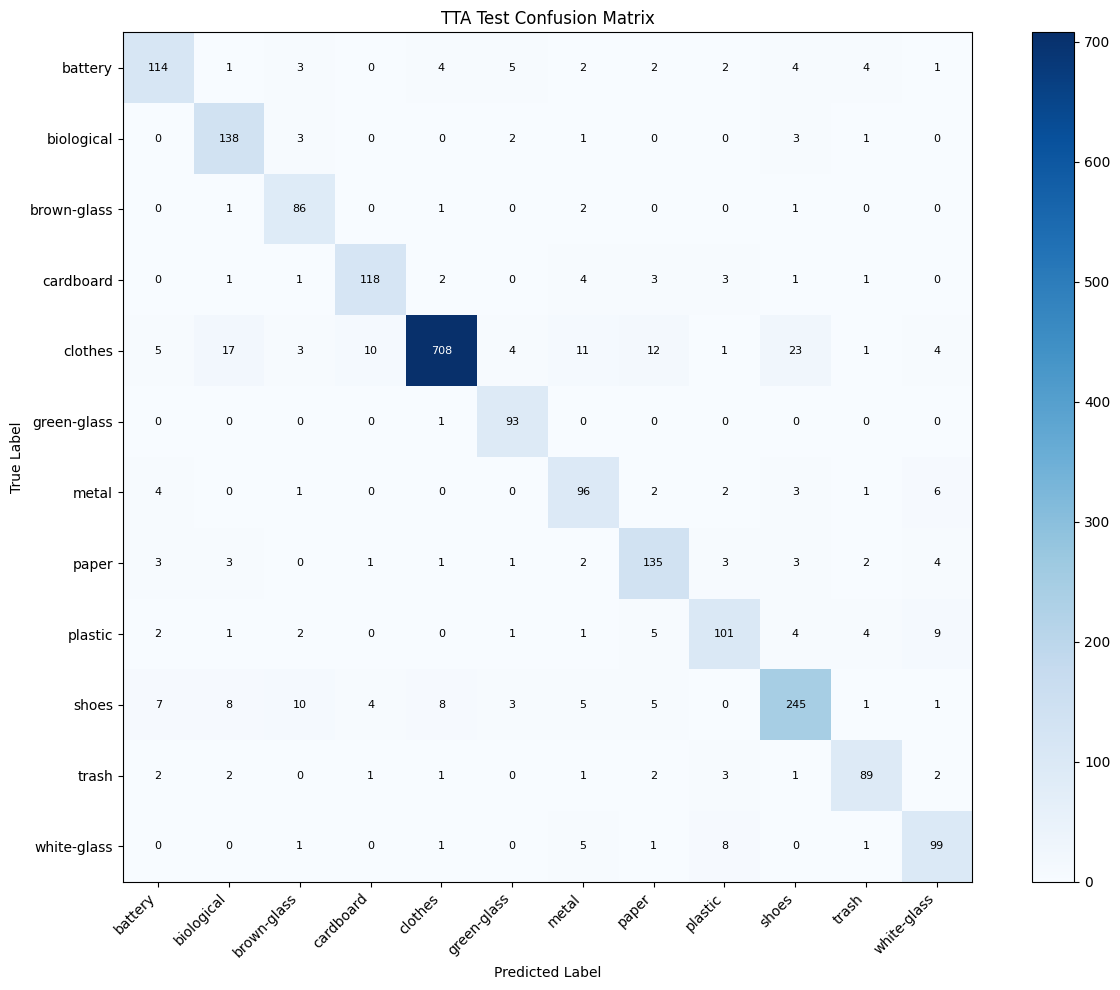

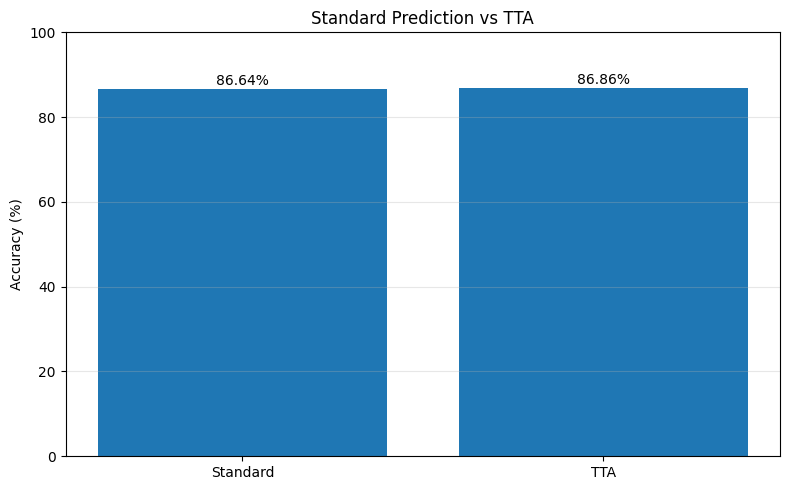


===== 7단계 TTA 실험 완료 =====
일반 예측 정확도: 86.64%
TTA 예측 정확도: 86.86%
정확도 변화: +0.21%p
일반 예측 오답에서 TTA 정답으로 변경: 49장
일반 예측 정답에서 TTA 오답으로 변경: 44장

저장된 파일
1. TTA 성능 비교표: /content/drive/MyDrive/garbage_classification_results/stage7_tta_metrics_comparison.csv
2. TTA 클래스별 보고서: /content/drive/MyDrive/garbage_classification_results/stage7_tta_classification_report.csv
3. TTA 혼동행렬: /content/drive/MyDrive/garbage_classification_results/13_stage7_tta_confusion_matrix.png
4. 정확도 비교 그래프: /content/drive/MyDrive/garbage_classification_results/14_stage7_tta_accuracy_comparison.png
5. TTA 이미지별 예측: /content/drive/MyDrive/garbage_classification_results/stage7_tta_test_predictions.csv
6. 일반 예측 및 TTA 비교: /content/drive/MyDrive/garbage_classification_results/stage7_standard_vs_tta_predictions.csv
7. 예측 변경 사례: /content/drive/MyDrive/garbage_classification_results/stage7_tta_changed_predictions.csv

===== TTA 전체 평가 완료 =====


In [14]:

# =========================================================
# 7단계: TTA(Test Time Augmentation) 성능 비교 실험
# 일반 예측 vs TTA 예측
# =========================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)


# =========================================================
# 1. 기존 단계 변수 확인
# =========================================================

required_variables = [
    "test_loader",
    "final_test_model",
    "all_labels",
    "all_predictions",
    "classes",
    "inference_transform",
    "RESULT_DIR"
]

for variable in required_variables:

    assert variable in globals(), (
        f"{variable} 변수가 없습니다. "
        "6단계 코드를 먼저 실행하세요."
    )

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

num_classes = len(classes)

os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 60)
print("===== 7단계 TTA 실험 환경 =====")
print("=" * 60)

print("사용 장치:", device)
print("클래스 수:", num_classes)
print("테스트 이미지:", len(test_loader.dataset))


# =========================================================
# 2. 테스트 이미지 경로 가져오기
# =========================================================

def get_tta_test_samples(dataset):

    # GarbageDataset 구조
    if (
        hasattr(dataset, "base_dataset")
        and hasattr(dataset, "indices")
    ):

        return [
            dataset.base_dataset.samples[int(i)]
            for i in dataset.indices
        ]

    # PyTorch Subset 구조
    if hasattr(dataset, "indices") and hasattr(dataset, "dataset"):

        base_samples = get_tta_test_samples(
            dataset.dataset
        )

        return [
            base_samples[int(i)]
            for i in dataset.indices
        ]

    # ImageFolder 구조
    if hasattr(dataset, "samples"):

        return list(dataset.samples)

    # 내부 dataset 구조
    if hasattr(dataset, "dataset"):

        return get_tta_test_samples(
            dataset.dataset
        )

    raise AttributeError(
        "테스트 데이터의 이미지 경로를 찾을 수 없습니다."
    )


test_samples_tta = get_tta_test_samples(
    test_loader.dataset
)

assert len(test_samples_tta) == len(all_labels), (
    "테스트 이미지와 기존 평가 결과의 개수가 다릅니다."
)

print("테스트 이미지 경로 확인:", len(test_samples_tta))


# =========================================================
# 3. TTA용 데이터셋 정의
# =========================================================

class TTATestDataset(Dataset):

    def __init__(self, samples, transform):

        self.samples = samples
        self.transform = transform

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        with Image.open(image_path) as img:

            original = img.convert("RGB")

        width, height = original.size

        # 중앙 80% 영역 계산
        margin_w = int(width * 0.1)
        margin_h = int(height * 0.1)

        center_crop = original.crop((
            margin_w,
            margin_h,
            width - margin_w,
            height - margin_h
        ))

        # 네 가지 이미지 시점
        views = [

            # 1. 원본
            original,

            # 2. 좌우 반전
            original.transpose(
                Image.Transpose.FLIP_LEFT_RIGHT
            ),

            # 3. 중앙 80% 크롭
            center_crop,

            # 4. 중앙 크롭 + 좌우 반전
            center_crop.transpose(
                Image.Transpose.FLIP_LEFT_RIGHT
            )

        ]

        # 동일한 기본 전처리 적용
        tensors = [
            self.transform(view)
            for view in views
        ]

        return torch.stack(tensors), int(label)


# =========================================================
# 4. TTA DataLoader 생성
# =========================================================

tta_dataset = TTATestDataset(
    samples=test_samples_tta,
    transform=inference_transform
)

TTA_BATCH_SIZE = 16
TTA_NUM_WORKERS = 2

tta_loader = DataLoader(
    tta_dataset,
    batch_size=TTA_BATCH_SIZE,
    shuffle=False,
    num_workers=TTA_NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    drop_last=False
)

print("\n===== TTA 데이터 준비 완료 =====")
print("이미지 시점:", 4)
print("배치 크기:", TTA_BATCH_SIZE)
print("테스트 이미지:", len(tta_dataset))


# =========================================================
# 5. 일반 예측 결과 확인
# =========================================================

standard_labels = np.asarray(
    all_labels,
    dtype=int
)

standard_predictions = np.asarray(
    all_predictions,
    dtype=int
)

assert len(standard_labels) == len(standard_predictions)

standard_accuracy = accuracy_score(
    standard_labels,
    standard_predictions
)

print("\n기존 일반 예측 정확도:")
print(f"{standard_accuracy * 100:.2f}%")


# =========================================================
# 6. TTA 예측 실행
# =========================================================

final_test_model.eval()

tta_labels = []
tta_predictions = []
tta_probabilities = []

print("\n" + "=" * 60)
print("===== TTA 테스트 시작 =====")
print("=" * 60)

with torch.inference_mode():

    for batch_idx, (views, labels) in enumerate(tta_loader):

        # views 형태:
        # [Batch, 4, Channel, Height, Width]

        views = views.to(
            device,
            non_blocking=True
        )

        batch_size = views.size(0)

        # 네 가지 시점의 확률 합산
        probability_sum = torch.zeros(
            batch_size,
            num_classes,
            device=device
        )

        # 메모리 절약을 위해 시점을 하나씩 예측
        for view_idx in range(4):

            current_view = views[:, view_idx]

            outputs = final_test_model(
                current_view
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            probability_sum += probabilities

        # 네 가지 결과의 확률 평균
        averaged_probabilities = (
            probability_sum / 4.0
        )

        predictions = averaged_probabilities.argmax(
            dim=1
        )

        tta_labels.extend(
            labels.numpy()
        )

        tta_predictions.extend(
            predictions.cpu().numpy()
        )

        tta_probabilities.extend(
            averaged_probabilities.cpu().numpy()
        )

        if (batch_idx + 1) % 10 == 0:

            print(
                f"진행 상황: "
                f"{batch_idx + 1}/{len(tta_loader)}"
            )


# NumPy 변환
tta_labels = np.asarray(
    tta_labels,
    dtype=int
)

tta_predictions = np.asarray(
    tta_predictions,
    dtype=int
)

tta_probabilities = np.asarray(
    tta_probabilities,
    dtype=float
)

tta_confidence = tta_probabilities.max(
    axis=1
)


# =========================================================
# 7. 테스트 정답 순서 확인
# =========================================================

assert np.array_equal(
    standard_labels,
    tta_labels
), (
    "일반 예측과 TTA 예측의 테스트 정답 순서가 다릅니다."
)

print("\n테스트 정답 순서 확인 완료!")


# =========================================================
# 8. TTA 성능 지표 계산
# =========================================================

tta_accuracy = accuracy_score(
    tta_labels,
    tta_predictions
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        tta_labels,
        tta_predictions,
        labels=list(range(num_classes)),
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        tta_labels,
        tta_predictions,
        labels=list(range(num_classes)),
        average="weighted",
        zero_division=0
    )
)

tta_balanced_accuracy = balanced_accuracy_score(
    tta_labels,
    tta_predictions
)


# =========================================================
# 9. 일반 예측과 TTA 성능 비교
# =========================================================

standard_macro_f1 = precision_recall_fscore_support(
    standard_labels,
    standard_predictions,
    labels=list(range(num_classes)),
    average="macro",
    zero_division=0
)[2]

standard_weighted_f1 = precision_recall_fscore_support(
    standard_labels,
    standard_predictions,
    labels=list(range(num_classes)),
    average="weighted",
    zero_division=0
)[2]

standard_macro_precision, standard_macro_recall, _, _ = (
    precision_recall_fscore_support(
        standard_labels,
        standard_predictions,
        labels=list(range(num_classes)),
        average="macro",
        zero_division=0
    )
)

standard_balanced_accuracy = balanced_accuracy_score(
    standard_labels,
    standard_predictions
)

comparison_df = pd.DataFrame([

    {
        "Method": "Standard Prediction",
        "Accuracy (%)": standard_accuracy * 100,
        "Macro Precision": standard_macro_precision,
        "Macro Recall": standard_macro_recall,
        "Macro F1": standard_macro_f1,
        "Weighted F1": standard_weighted_f1,
        "Balanced Accuracy": standard_balanced_accuracy
    },

    {
        "Method": "TTA Prediction",
        "Accuracy (%)": tta_accuracy * 100,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Balanced Accuracy": tta_balanced_accuracy
    }

])

print("\n" + "=" * 60)
print("===== 일반 예측 vs TTA 성능 비교 =====")
print("=" * 60)

print(
    comparison_df.round(4).to_string(index=False)
)

accuracy_improvement = (
    tta_accuracy - standard_accuracy
) * 100

macro_f1_improvement = (
    macro_f1 - standard_macro_f1
)

print("\n===== TTA 성능 변화 =====")

print(
    f"정확도 변화: {accuracy_improvement:+.2f}%p"
)

print(
    f"Macro F1 변화: {macro_f1_improvement:+.4f}"
)


# =========================================================
# 10. 정분류 및 오분류 변화 분석
# =========================================================

standard_correct = (
    standard_labels == standard_predictions
)

tta_correct = (
    tta_labels == tta_predictions
)

improved_cases = np.where(
    (~standard_correct) & tta_correct
)[0]

worsened_cases = np.where(
    standard_correct & (~tta_correct)
)[0]

unchanged_wrong_cases = np.where(
    (~standard_correct) & (~tta_correct)
)[0]

unchanged_correct_cases = np.where(
    standard_correct & tta_correct
)[0]

print("\n===== 예측 결과 변화 분석 =====")

print(
    "일반 예측 오답 → TTA 정답:",
    len(improved_cases)
)

print(
    "일반 예측 정답 → TTA 오답:",
    len(worsened_cases)
)

print(
    "두 방식 모두 정답:",
    len(unchanged_correct_cases)
)

print(
    "두 방식 모두 오답:",
    len(unchanged_wrong_cases)
)


# =========================================================
# 11. TTA Classification Report
# =========================================================

tta_report = classification_report(
    tta_labels,
    tta_predictions,
    labels=list(range(num_classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

tta_report_df = pd.DataFrame(
    tta_report
).transpose()

print("\n===== TTA 클래스별 성능 =====")

print(
    classification_report(
        tta_labels,
        tta_predictions,
        labels=list(range(num_classes)),
        target_names=classes,
        zero_division=0
    )
)


# =========================================================
# 12. TTA Confusion Matrix
# =========================================================

tta_cm = confusion_matrix(
    tta_labels,
    tta_predictions,
    labels=list(range(num_classes))
)

plt.figure(figsize=(13, 10))

plt.imshow(
    tta_cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("TTA Test Confusion Matrix")
plt.colorbar()

plt.xticks(
    range(num_classes),
    classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(num_classes),
    classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = (
    tta_cm.max() / 2
    if tta_cm.max() > 0
    else 0
)

for i in range(num_classes):

    for j in range(num_classes):

        plt.text(
            j,
            i,
            str(tta_cm[i, j]),
            ha="center",
            va="center",
            color=(
                "white"
                if tta_cm[i, j] > threshold
                else "black"
            ),
            fontsize=8
        )

plt.tight_layout()

TTA_CM_PATH = os.path.join(
    RESULT_DIR,
    "13_stage7_tta_confusion_matrix.png"
)

plt.savefig(
    TTA_CM_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 13. 일반 예측과 TTA 정확도 비교 그래프
# =========================================================

methods = [
    "Standard",
    "TTA"
]

accuracies = [
    standard_accuracy * 100,
    tta_accuracy * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    methods,
    accuracies
)

plt.title("Standard Prediction vs TTA")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    accuracies
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

TTA_GRAPH_PATH = os.path.join(
    RESULT_DIR,
    "14_stage7_tta_accuracy_comparison.png"
)

plt.savefig(
    TTA_GRAPH_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 14. TTA 예측 결과 CSV 저장
# =========================================================

tta_top3_indices = np.argsort(
    tta_probabilities,
    axis=1
)[:, -3:][:, ::-1]

tta_prediction_df = pd.DataFrame({

    "Image_Path": [
        sample[0]
        for sample in test_samples_tta
    ],

    "True_Label": [
        classes[i]
        for i in tta_labels
    ],

    "Predicted_Label": [
        classes[i]
        for i in tta_predictions
    ],

    "Confidence": tta_confidence,

    "Confidence_Percent": (
        tta_confidence * 100
    ),

    "Top2_Label": [
        classes[i]
        for i in tta_top3_indices[:, 1]
    ],

    "Top3_Label": [
        classes[i]
        for i in tta_top3_indices[:, 2]
    ],

    "Correct": (
        tta_labels == tta_predictions
    )

})

TTA_PREDICTION_PATH = os.path.join(
    RESULT_DIR,
    "stage7_tta_test_predictions.csv"
)

tta_prediction_df.to_csv(
    TTA_PREDICTION_PATH,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 15. 일반 예측과 TTA 개별 결과 비교 저장
# =========================================================

method_comparison_df = pd.DataFrame({

    "Image_Path": [
        sample[0]
        for sample in test_samples_tta
    ],

    "True_Label": [
        classes[i]
        for i in standard_labels
    ],

    "Standard_Prediction": [
        classes[i]
        for i in standard_predictions
    ],

    "TTA_Prediction": [
        classes[i]
        for i in tta_predictions
    ],

    "Standard_Correct": standard_correct,

    "TTA_Correct": tta_correct,

    "TTA_Confidence": tta_confidence

})

METHOD_COMPARISON_PATH = os.path.join(
    RESULT_DIR,
    "stage7_standard_vs_tta_predictions.csv"
)

method_comparison_df.to_csv(
    METHOD_COMPARISON_PATH,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 16. TTA 성능 요약표 저장
# =========================================================

TTA_METRICS_PATH = os.path.join(
    RESULT_DIR,
    "stage7_tta_metrics_comparison.csv"
)

comparison_df.to_csv(
    TTA_METRICS_PATH,
    index=False,
    encoding="utf-8-sig"
)

TTA_REPORT_PATH = os.path.join(
    RESULT_DIR,
    "stage7_tta_classification_report.csv"
)

tta_report_df.to_csv(
    TTA_REPORT_PATH,
    encoding="utf-8-sig"
)


# =========================================================
# 17. TTA 개선 및 악화 사례 저장
# =========================================================

change_rows = []

for idx in improved_cases:

    change_rows.append({

        "Image_Path": test_samples_tta[idx][0],

        "True_Label": classes[tta_labels[idx]],

        "Standard_Prediction": classes[
            standard_predictions[idx]
        ],

        "TTA_Prediction": classes[
            tta_predictions[idx]
        ],

        "Change": "Improved"

    })


for idx in worsened_cases:

    change_rows.append({

        "Image_Path": test_samples_tta[idx][0],

        "True_Label": classes[tta_labels[idx]],

        "Standard_Prediction": classes[
            standard_predictions[idx]
        ],

        "TTA_Prediction": classes[
            tta_predictions[idx]
        ],

        "Change": "Worsened"

    })


change_df = pd.DataFrame(change_rows)

CHANGE_PATH = os.path.join(
    RESULT_DIR,
    "stage7_tta_changed_predictions.csv"
)

change_df.to_csv(
    CHANGE_PATH,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 18. 결과 객체 저장
# =========================================================

stage7_results = {

    "standard_accuracy": standard_accuracy,

    "tta_accuracy": tta_accuracy,

    "accuracy_improvement": accuracy_improvement,

    "macro_precision": macro_precision,

    "macro_recall": macro_recall,

    "macro_f1": macro_f1,

    "weighted_f1": weighted_f1,

    "balanced_accuracy": tta_balanced_accuracy,

    "confusion_matrix": tta_cm,

    "classification_report": tta_report_df,

    "improved_cases": improved_cases,

    "worsened_cases": worsened_cases,

    "tta_predictions": tta_predictions,

    "tta_probabilities": tta_probabilities

}


# =========================================================
# 19. 최종 결과 출력
# =========================================================

print("\n" + "=" * 60)
print("===== 7단계 TTA 실험 완료 =====")
print("=" * 60)

print(
    f"일반 예측 정확도: "
    f"{standard_accuracy * 100:.2f}%"
)

print(
    f"TTA 예측 정확도: "
    f"{tta_accuracy * 100:.2f}%"
)

print(
    f"정확도 변화: "
    f"{accuracy_improvement:+.2f}%p"
)

print(
    f"일반 예측 오답에서 TTA 정답으로 변경: "
    f"{len(improved_cases)}장"
)

print(
    f"일반 예측 정답에서 TTA 오답으로 변경: "
    f"{len(worsened_cases)}장"
)

print("\n저장된 파일")

print("1. TTA 성능 비교표:", TTA_METRICS_PATH)

print("2. TTA 클래스별 보고서:", TTA_REPORT_PATH)

print("3. TTA 혼동행렬:", TTA_CM_PATH)

print("4. 정확도 비교 그래프:", TTA_GRAPH_PATH)

print("5. TTA 이미지별 예측:", TTA_PREDICTION_PATH)

print("6. 일반 예측 및 TTA 비교:", METHOD_COMPARISON_PATH)

print("7. 예측 변경 사례:", CHANGE_PATH)

print("\n===== TTA 전체 평가 완료 =====")


In [15]:
# ============================================================
# 8단계. Weighted Sampling 기반 클래스 불균형 개선
# ============================================================

import os
import copy
import time
import torch
import numpy as np

from torch import nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

print("=" * 70)
print("Stage 8: Weighted Sampling Fine-tuning")
print("=" * 70)

# ------------------------------------------------------------
# 1. 환경 및 데이터 확인
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("사용 장치:", device)
print("학습 데이터:", len(train_dataset_aug))
print("검증 데이터:", len(val_dataset_stage4))

# ------------------------------------------------------------
# 2. 학습 데이터 클래스 분포 확인
# ------------------------------------------------------------

# train_samples는 (이미지 경로, 클래스 번호) 형태라고 가정
train_labels_stage8 = np.array(
    [label for _, label in train_samples],
    dtype=np.int64
)

num_classes_stage8 = len(classes)

class_counts_stage8 = np.bincount(
    train_labels_stage8,
    minlength=num_classes_stage8
)

print("\n===== 학습 데이터 클래스 분포 =====")

for i, class_name in enumerate(classes):
    print(f"{class_name:20s}: {class_counts_stage8[i]:,}")

# ------------------------------------------------------------
# 3. WeightedRandomSampler 생성
# ------------------------------------------------------------

# 클래스별 데이터 수가 적을수록 샘플링 가중치를 높임
# 1 / sqrt(class_count)를 사용하여 지나친 보정을 방지

class_sample_weights_stage8 = (
    1.0 / np.sqrt(np.maximum(class_counts_stage8, 1))
)

sample_weights_stage8 = (
    class_sample_weights_stage8[train_labels_stage8]
)

sample_weights_stage8 = torch.DoubleTensor(
    sample_weights_stage8
)

sampler_stage8 = WeightedRandomSampler(
    weights=sample_weights_stage8,
    num_samples=len(train_dataset_aug),
    replacement=True
)

# ------------------------------------------------------------
# 4. DataLoader 생성
# ------------------------------------------------------------

train_loader_stage8 = DataLoader(
    train_dataset_aug,
    batch_size=32,
    sampler=sampler_stage8,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader_stage8 = DataLoader(
    val_dataset_stage4,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("\nDataLoader 생성 완료")
print("학습 배치 수:", len(train_loader_stage8))
print("검증 배치 수:", len(val_loader_stage8))

# ------------------------------------------------------------
# 5. 기존 5단계 최적 모델 불러오기
# ------------------------------------------------------------

stage8_model = ImprovedGarbageCNN(num_classes=len(classes)).to(device)

checkpoint_path_stage8 = (
    "/content/drive/MyDrive/garbage_classification_results/"
    "final_tuned_garbage_cnn.pth"
)

checkpoint_stage8 = torch.load(
    checkpoint_path_stage8,
    map_location=device,
    weights_only=True
)

# 체크포인트 형태에 따라 state_dict 추출
if isinstance(checkpoint_stage8, dict) and "state_dict" in checkpoint_stage8:
    checkpoint_stage8 = checkpoint_stage8["state_dict"]

elif isinstance(checkpoint_stage8, dict) and "model_state_dict" in checkpoint_stage8:
    checkpoint_stage8 = checkpoint_stage8["model_state_dict"]

stage8_model.load_state_dict(checkpoint_stage8)

print("\n5단계 최적 모델 불러오기 완료")

# ------------------------------------------------------------
# 6. Loss, Optimizer, Scheduler 설정
# ------------------------------------------------------------

# WeightedRandomSampler로 클래스 불균형을 보정하므로
# Loss에 별도의 클래스 가중치는 적용하지 않음

criterion_stage8 = nn.CrossEntropyLoss(
    label_smoothing=0.03
)

optimizer_stage8 = torch.optim.AdamW(
    stage8_model.parameters(),
    lr=0.00005,
    weight_decay=0.0001
)

epochs_stage8 = 12

scheduler_stage8 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_stage8,
    T_max=epochs_stage8,
    eta_min=1e-6
)

# ------------------------------------------------------------
# 7. 학습 및 검증
# ------------------------------------------------------------

best_val_loss_stage8 = float("inf")
best_val_acc_stage8 = 0.0

best_weights_stage8 = None

patience_stage8 = 4
early_stop_counter_stage8 = 0

history_stage8 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

start_time_stage8 = time.time()

for epoch in range(epochs_stage8):

    # ========================================================
    # Training
    # ========================================================

    stage8_model.train()

    train_loss_sum_stage8 = 0.0
    train_correct_stage8 = 0
    train_total_stage8 = 0

    for images, labels in train_loader_stage8:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_stage8.zero_grad(set_to_none=True)

        outputs = stage8_model(images)

        loss = criterion_stage8(outputs, labels)

        loss.backward()

        # Gradient Clipping
        torch.nn.utils.clip_grad_norm_(
            stage8_model.parameters(),
            max_norm=2.0
        )

        optimizer_stage8.step()

        train_loss_sum_stage8 += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct_stage8 += (
            predictions == labels
        ).sum().item()

        train_total_stage8 += labels.size(0)

    train_loss_stage8 = (
        train_loss_sum_stage8 / train_total_stage8
    )

    train_acc_stage8 = (
        train_correct_stage8 / train_total_stage8
    )

    # ========================================================
    # Validation
    # ========================================================

    stage8_model.eval()

    val_loss_sum_stage8 = 0.0
    val_correct_stage8 = 0
    val_total_stage8 = 0

    with torch.inference_mode():

        for images, labels in val_loader_stage8:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = stage8_model(images)

            loss = criterion_stage8(outputs, labels)

            val_loss_sum_stage8 += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_correct_stage8 += (
                predictions == labels
            ).sum().item()

            val_total_stage8 += labels.size(0)

    val_loss_stage8 = (
        val_loss_sum_stage8 / val_total_stage8
    )

    val_acc_stage8 = (
        val_correct_stage8 / val_total_stage8
    )

    # 기록 저장
    history_stage8["train_loss"].append(train_loss_stage8)
    history_stage8["train_acc"].append(train_acc_stage8)

    history_stage8["val_loss"].append(val_loss_stage8)
    history_stage8["val_acc"].append(val_acc_stage8)

    # Learning Rate
    current_lr_stage8 = optimizer_stage8.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1:02d}/{epochs_stage8}] "
        f"Train Loss: {train_loss_stage8:.4f} | "
        f"Train Acc: {train_acc_stage8*100:.2f}% | "
        f"Val Loss: {val_loss_stage8:.4f} | "
        f"Val Acc: {val_acc_stage8*100:.2f}% | "
        f"LR: {current_lr_stage8:.6f}"
    )

    # ========================================================
    # Best Model 저장 (Validation Loss 기준)
    # ========================================================

    if val_loss_stage8 < best_val_loss_stage8:

        best_val_loss_stage8 = val_loss_stage8
        best_val_acc_stage8 = val_acc_stage8

        best_weights_stage8 = {
            key: value.detach().cpu().clone()
            for key, value in stage8_model.state_dict().items()
        }

        early_stop_counter_stage8 = 0

        print("  -> 검증 손실 개선: 최적 가중치 저장")

    else:

        early_stop_counter_stage8 += 1

        print(
            f"  -> 검증 손실 개선 없음 "
            f"({early_stop_counter_stage8}/{patience_stage8})"
        )

    # Scheduler 업데이트
    scheduler_stage8.step()

    # ========================================================
    # Early Stopping
    # ========================================================

    if early_stop_counter_stage8 >= patience_stage8:

        print("\nEarly Stopping 실행")
        break

# ------------------------------------------------------------
# 8. 최적 가중치 복원 및 저장
# ------------------------------------------------------------

if best_weights_stage8 is not None:

    stage8_model.load_state_dict(best_weights_stage8)

    stage8_model.to(device)

    stage8_model.eval()

    save_path_stage8 = os.path.join(
        RESULT_DIR,
        "stage8_weighted_finetuned_cnn.pth"
    )

    torch.save(
        stage8_model.state_dict(),
        save_path_stage8
    )

    print("\n최적 모델 복원 완료")

    print(
        f"Best Validation Loss: "
        f"{best_val_loss_stage8:.4f}"
    )

    print(
        f"Best Validation Accuracy: "
        f"{best_val_acc_stage8*100:.2f}%"
    )

    print("모델 저장 경로:", save_path_stage8)

# ------------------------------------------------------------
# 9. 학습 시간 확인
# ------------------------------------------------------------

elapsed_time_stage8 = (
    time.time() - start_time_stage8
)

print(
    f"\nStage 8 학습 시간: "
    f"{elapsed_time_stage8/60:.2f}분"
)

print("=" * 70)
print("Stage 8 학습 완료")
print("=" * 70)

Stage 8: Weighted Sampling Fine-tuning
사용 장치: cuda
학습 데이터: 10860
검증 데이터: 2327

===== 학습 데이터 클래스 분포 =====
battery             : 661
biological          : 689
brown-glass         : 425
cardboard           : 624
clothes             : 3,727
green-glass         : 440
metal               : 538
paper               : 735
plastic             : 606
shoes               : 1,384
trash               : 488
white-glass         : 543

DataLoader 생성 완료
학습 배치 수: 340
검증 배치 수: 73

5단계 최적 모델 불러오기 완료
Epoch [01/12] Train Loss: 0.5583 | Train Acc: 88.43% | Val Loss: 0.5769 | Val Acc: 87.11% | LR: 0.000050
  -> 검증 손실 개선: 최적 가중치 저장
Epoch [02/12] Train Loss: 0.5326 | Train Acc: 89.01% | Val Loss: 0.5724 | Val Acc: 87.06% | LR: 0.000049
  -> 검증 손실 개선: 최적 가중치 저장
Epoch [03/12] Train Loss: 0.5341 | Train Acc: 88.78% | Val Loss: 0.5816 | Val Acc: 86.85% | LR: 0.000047
  -> 검증 손실 개선 없음 (1/4)
Epoch [04/12] Train Loss: 0.5164 | Train Acc: 89.93% | Val Loss: 0.5628 | Val Acc: 87.11% | LR: 0.000043
  -> 검증 손실 개선: 최적 가중치 저장

Stage 9: Stage 5 vs Stage 8 최종 성능 비교
사용 장치: cuda
Stage 5 모델 불러오기 완료
Stage 8 모델 불러오기 완료

테스트 데이터 평가 시작...
평가 완료

최종 모델 성능 비교
평가지표                             Stage 5        Stage 8             차이
----------------------------------------------------------------------
Accuracy                       86.6409%      88.2732%      +1.6323%
Balanced Accuracy              86.5109%      85.6811%      -0.8298%
Macro F1                       84.5317%      85.6681%      +1.1364%
Weighted F1                    86.7672%      88.2474%      +1.4802%

Stage 5 클래스별 성능
              precision    recall  f1-score   support

     battery     0.8261    0.8028    0.8143       142
  biological     0.7988    0.9122    0.8517       148
 brown-glass     0.7838    0.9560    0.8614        91
   cardboard     0.8872    0.8806    0.8839       134
     clothes     0.9793    0.8886    0.9318       799
 green-glass     0.8411    0.9574    0.8955        94
       metal     0.7500    0.8348    0.7901       115
       paper

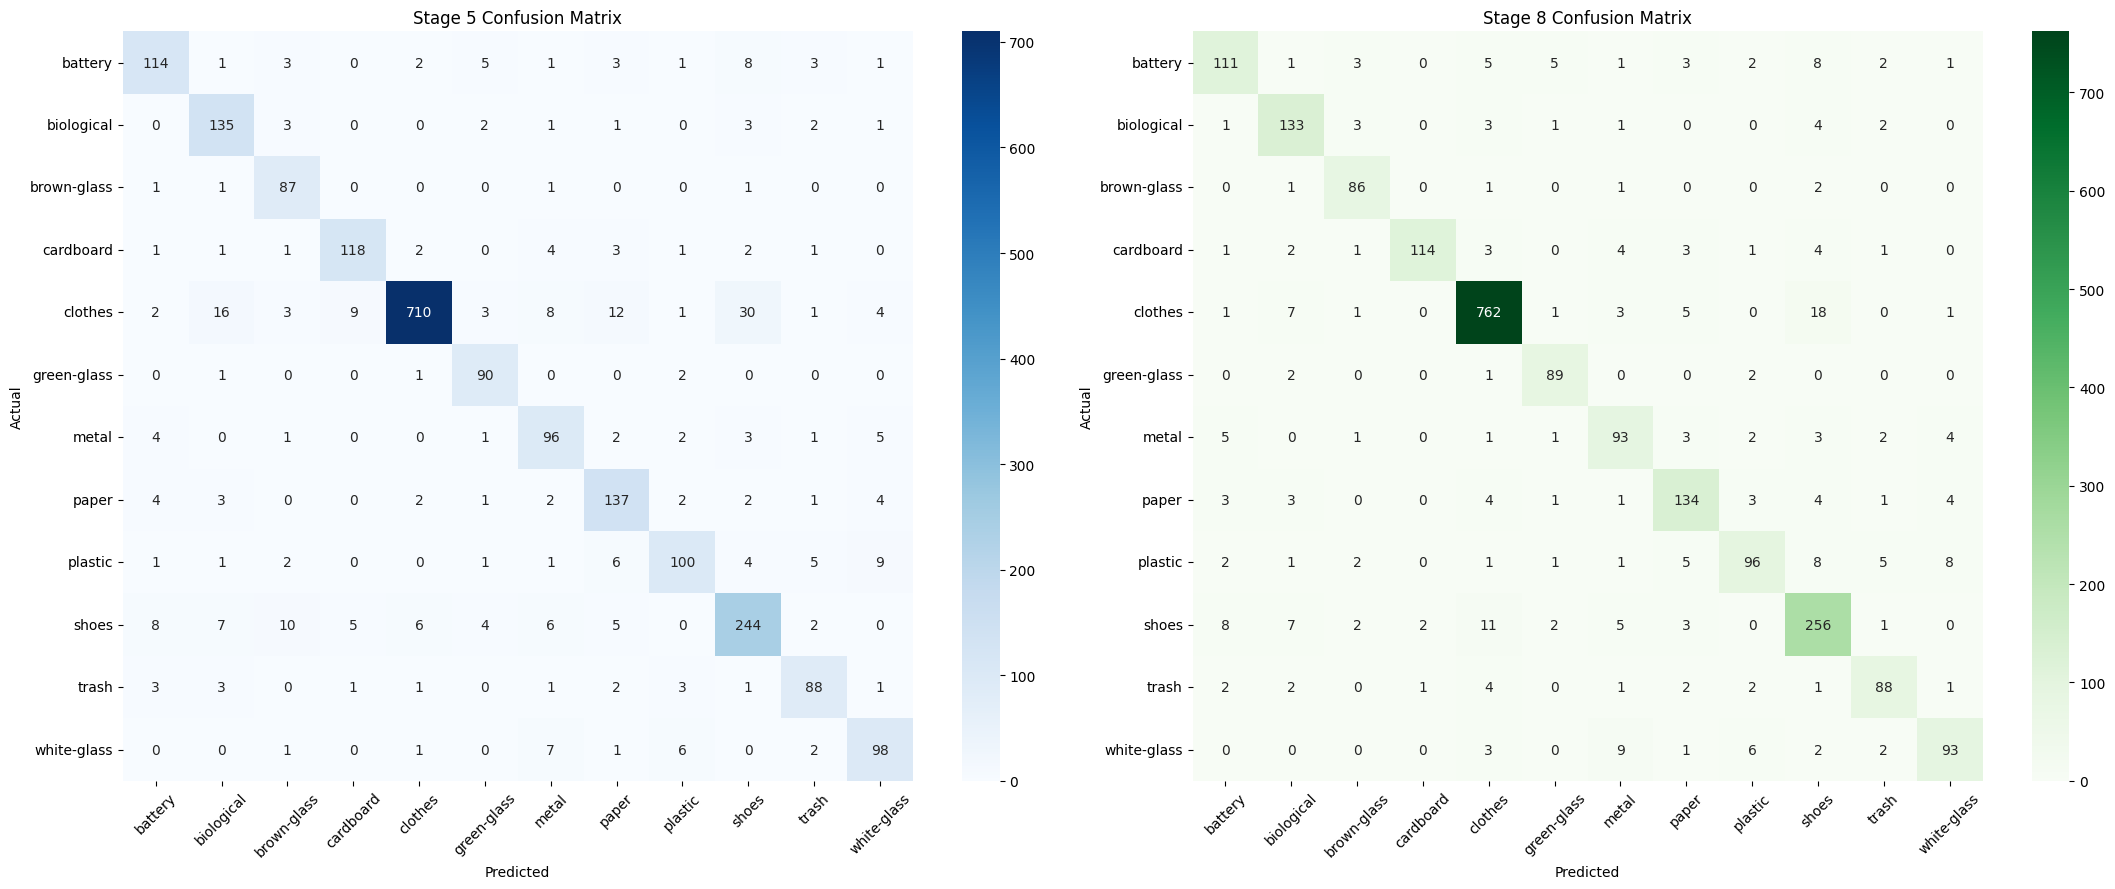


Stage 9 최종 비교 완료!


In [16]:
# ============================================================
# Stage 9: Stage 5 vs Stage 8 최종 성능 비교
# ============================================================

import torch
import numpy as np
import os
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("Stage 9: Stage 5 vs Stage 8 최종 성능 비교")
print("=" * 70)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

# ------------------------------------------------------------
# 1. Stage 5 모델 불러오기
# ------------------------------------------------------------

stage5_model = ImprovedGarbageCNN(num_classes=len(classes)).to(device)

stage5_model.load_state_dict(best_stage5_result["state_dict"])
stage5_model.eval()

print("Stage 5 모델 불러오기 완료")

# ------------------------------------------------------------
# 2. Stage 8 모델 불러오기
# ------------------------------------------------------------

stage8_model = ImprovedGarbageCNN(num_classes=len(classes)).to(device)

checkpoint_path_stage8 = (
    "/content/drive/MyDrive/garbage_classification_results/"
    "stage8_weighted_finetuned_cnn.pth"
)

checkpoint_stage8 = torch.load(
    checkpoint_path_stage8,
    map_location=device
)

# 저장된 체크포인트 형태에 따라 처리
if isinstance(checkpoint_stage8, dict) and "state_dict" in checkpoint_stage8:
    stage8_state_dict = checkpoint_stage8["state_dict"]
else:
    stage8_state_dict = checkpoint_stage8

stage8_model.load_state_dict(stage8_state_dict)
stage8_model.eval()

print("Stage 8 모델 불러오기 완료")

# ------------------------------------------------------------
# 3. 테스트 데이터 평가 함수
# ------------------------------------------------------------

def evaluate_final_model(model, test_loader, device):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    balanced_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    weighted_f1 = f1_score(y_true, y_pred, average="weighted")

    return {
        "y_true": y_true,
        "y_pred": y_pred,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_acc,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

# ------------------------------------------------------------
# 4. 두 모델 동일 테스트 데이터 평가
# ------------------------------------------------------------

print("\n테스트 데이터 평가 시작...")

stage5_results = evaluate_final_model(
    stage5_model,
    test_loader,
    device
)

stage8_results = evaluate_final_model(
    stage8_model,
    test_loader,
    device
)

print("평가 완료")

# ------------------------------------------------------------
# 5. 성능 비교표 출력
# ------------------------------------------------------------

comparison = {
    "Stage 5": stage5_results,
    "Stage 8": stage8_results
}

print("\n" + "=" * 70)
print("최종 모델 성능 비교")
print("=" * 70)

print(f"{'평가지표':<25}{'Stage 5':>15}{'Stage 8':>15}{'차이':>15}")
print("-" * 70)

metrics = [
    ("Accuracy", "accuracy"),
    ("Balanced Accuracy", "balanced_accuracy"),
    ("Macro F1", "macro_f1"),
    ("Weighted F1", "weighted_f1")
]

for metric_name, metric_key in metrics:

    s5 = stage5_results[metric_key]
    s8 = stage8_results[metric_key]
    diff = s8 - s5

    print(
        f"{metric_name:<25}"
        f"{s5:>14.4%}"
        f"{s8:>14.4%}"
        f"{diff:>+14.4%}"
    )

# ------------------------------------------------------------
# 6. 클래스별 Classification Report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("Stage 5 클래스별 성능")
print("=" * 70)

print(classification_report(
    stage5_results["y_true"],
    stage5_results["y_pred"],
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4,
    zero_division=0
))

print("\n" + "=" * 70)
print("Stage 8 클래스별 성능")
print("=" * 70)

print(classification_report(
    stage8_results["y_true"],
    stage8_results["y_pred"],
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4,
    zero_division=0
))

# ------------------------------------------------------------
# 7. 클래스별 Recall 비교
# ------------------------------------------------------------

report5 = classification_report(
    stage5_results["y_true"],
    stage5_results["y_pred"],
    labels=np.arange(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report8 = classification_report(
    stage8_results["y_true"],
    stage8_results["y_pred"],
    labels=np.arange(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

print("\n" + "=" * 70)
print("클래스별 Recall 비교")
print("=" * 70)

print(f"{'Class':<20}{'Stage 5':>12}{'Stage 8':>12}{'차이':>12}")
print("-" * 60)

for cls in classes:

    recall5 = report5[cls]["recall"]
    recall8 = report8[cls]["recall"]

    print(
        f"{cls:<20}"
        f"{recall5:>11.4f}"
        f"{recall8:>11.4f}"
        f"{recall8-recall5:>+11.4f}"
    )

# ------------------------------------------------------------
# 8. Confusion Matrix 비교
# ------------------------------------------------------------

cm_stage5 = confusion_matrix(
    stage5_results["y_true"],
    stage5_results["y_pred"],
    labels=np.arange(len(classes))
)

cm_stage8 = confusion_matrix(
    stage8_results["y_true"],
    stage8_results["y_pred"],
    labels=np.arange(len(classes))
)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

sns.heatmap(
    cm_stage5,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    ax=axes[0]
)

axes[0].set_title("Stage 5 Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].tick_params(axis="x", rotation=45)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_stage8,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes,
    ax=axes[1]
)

axes[1].set_title("Stage 8 Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

print("\nStage 9 최종 비교 완료!")

In [ ]:

# ============================================================
# Stage 10: 최종 모델 저장 및 실제 이미지 예측 테스트
# ============================================================

import torch
import torch.nn.functional as F
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

print("=" * 70)
print("Stage 10: 최종 모델 저장 및 실제 이미지 예측")
print("=" * 70)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

# ------------------------------------------------------------
# 1. 최종 모델 불러오기
# ------------------------------------------------------------

final_model = ImprovedGarbageCNN(num_classes=len(classes)).to(device)

# GitHub에서 다운로드한 최종 모델 파일 불러오기
from google.colab import files
import os

checkpoint_path = "/content/final_garbage_classification_model.pth"

# 모델 파일이 없으면 직접 업로드
if not os.path.exists(checkpoint_path):
    print("최종 모델 파일을 업로드하세요.")
    uploaded_model = files.upload()

    if "final_garbage_classification_model.pth" not in uploaded_model:
        raise FileNotFoundError("최종 모델 파일이 업로드되지 않았습니다.")

print("모델 파일 확인 완료:", checkpoint_path)

checkpoint = torch.load(checkpoint_path, map_location=device)

if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    final_model.load_state_dict(checkpoint["state_dict"])
else:
    final_model.load_state_dict(checkpoint)

final_model.eval()

print("Stage 8 최종 모델 불러오기 완료")

# ------------------------------------------------------------
# 2. 최종 모델 별도 저장
# ------------------------------------------------------------

RESULT_DIR = "/content/drive/MyDrive/garbage_classification_results"
os.makedirs(RESULT_DIR, exist_ok=True)

final_model_path = os.path.join(
    RESULT_DIR,
    "final_garbage_classification_model.pth"
)

torch.save({
    "state_dict": final_model.state_dict(),
    "classes": classes,
    "num_classes": len(classes)
}, final_model_path)

print("최종 모델 저장 완료:")
print(final_model_path)

# ------------------------------------------------------------
# 3. 테스트 데이터의 전처리 방식 가져오기
# ------------------------------------------------------------

def find_dataset_transform(dataset):
    current = dataset

    for _ in range(10):
        if hasattr(current, "transform") and current.transform is not None:
            return current.transform

        if hasattr(current, "dataset"):
            current = current.dataset
        else:
            break

    raise ValueError(
        "테스트 데이터의 transform을 찾지 못했습니다. "
        "test_loader.dataset의 전처리 설정을 확인하세요."
    )

inference_transform = find_dataset_transform(test_loader.dataset)

print("테스트 데이터와 동일한 이미지 전처리 방식 적용 완료")

# ------------------------------------------------------------
# 4. 이미지 예측 함수
# ------------------------------------------------------------

def predict_garbage_image(image_path, top_k=3):

    image = Image.open(image_path).convert("RGB")

    input_tensor = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = final_model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    top_k = min(top_k, len(classes))
    top_probs, top_indices = torch.topk(probabilities, top_k)

    predicted_class = classes[top_indices[0].item()]
    confidence = top_probs[0].item() * 100

    # 이미지 및 예측 결과 출력
    plt.figure(figsize=(7, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("\n===== 이미지 분류 결과 =====")
    print("예측 클래스:", predicted_class)
    print(f"예측 확률: {confidence:.2f}%")

    print("\n===== 상위 예측 결과 =====")

    for rank, (prob, index) in enumerate(
        zip(top_probs, top_indices), start=1
    ):
        print(
            f"{rank}위: {classes[index.item()]:<15}"
            f"{prob.item() * 100:.2f}%"
        )

    return predicted_class, confidence

# ------------------------------------------------------------
# 5. 실제 이미지 업로드 및 예측
# ------------------------------------------------------------

print("\n실제 쓰레기 이미지를 업로드하세요.")
uploaded = files.upload()

if len(uploaded) == 0:
    print("업로드된 이미지가 없습니다.")

else:
    for filename in uploaded.keys():

        print("\n" + "=" * 60)
        print("이미지:", filename)
        print("=" * 60)

        try:
            predict_garbage_image(filename, top_k=3)

        except Exception as e:
            print("이미지 예측 중 오류 발생:", e)

print("\n" + "=" * 70)
print("Stage 10 완료!")
print("=" * 70)


Stage 10: 최종 모델 저장 및 실제 이미지 예측
사용 장치: cuda
최종 모델 파일을 업로드하세요.
